# Evaluación Parcial N°1 — Deep Learning (DLY0100)
## Clasificación de prendas de vestir con una Red Neuronal Multicapa (MLP)

**Asignatura:** Deep Learning (DLY0100) · **Evaluación:** EP1 — 30%
**Alumno:** Demis Zuñiga
**Dataset:** Fashion-MNIST (entregado por el docente)
**Framework:** TensorFlow 2 / Keras 3

> **Este cuaderno es el informe.** Tal como pide la pauta, cada decisión de diseño,
> preprocesamiento, arquitectura e hiperparámetro está justificada en celdas Markdown
> junto al código que la implementa.

### Guía de lectura

| Sección | Contenido |
|---|---|
| 1 | Introducción: problema, objetivo y métricas de éxito |
| 2 | Carga de datos, análisis exploratorio y preprocesamiento |
| 3 | Definición del modelo: arquitectura, activaciones, pérdida, optimizador |
| 4 | Entrenamiento y **experimentos controlados** (una variable a la vez) |
| 5 | Evaluación: accuracy, precision, recall, F1 y matriz de confusión |
| 6 | Análisis y mejora: comparación de funciones y técnicas de regularización |
| 7 | Reentrenamiento del modelo final |
| 8 | Conclusiones |

## 1. Introducción

### El problema

Una empresa de comercio electrónico recibe miles de fotografías de productos y necesita
**clasificarlas automáticamente por categoría**. Hoy esa tarea la hace una persona a mano:
lenta, cara y propensa a errores. La pregunta del negocio es directa: *¿podemos construir un
sistema que aprenda a reconocer el tipo de prenda a partir de la imagen?*

Formulamos esto como un problema de **clasificación supervisada de imágenes**:

> Dada una imagen en escala de grises de 28×28 píxeles de una prenda de vestir, predecir a
> cuál de las **10 categorías** pertenece.

Las 10 categorías (los índices son los que usa el dataset):

| Índice | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|---|
| Prenda | Camiseta | Pantalón | Suéter | Vestido | Abrigo | Sandalia | Camisa | Zapatilla | Bolso | Botín |

### Por qué este dataset es interesante (y difícil)

Fashion-MNIST tiene la misma forma que el clásico MNIST de dígitos, pero **las clases son
mucho más parecidas entre sí**: una camiseta, una camisa y un suéter son visualmente casi
idénticas a 28×28 píxeles. Eso lo hace ideal para el objetivo de esta evaluación: no se trata
de obtener un número alto, sino de **entender cómo aprende la red y por qué ciertas
configuraciones funcionan mejor que otras**.

### Objetivo general

Implementar, entrenar y evaluar una red neuronal multicapa (MLP) en TensorFlow/Keras que
clasifique prendas de vestir, **justificando cada decisión técnica con evidencia experimental**.

### Objetivos específicos

1. Cargar y preprocesar los datos justificando cada transformación.
2. Diseñar una arquitectura MLP justificando capas, neuronas y funciones.
3. Configurar los hiperparámetros clave: épocas, tasa de aprendizaje y tamaño de batch.
4. **Analizar el impacto de cada hiperparámetro con experimentos controlados**, variando una
   variable a la vez.
5. Comparar el rendimiento de distintas **funciones de activación y de pérdida**.
6. Aplicar **técnicas de optimización y regularización** (dropout, batch normalization) y medir
   su efecto sobre la estabilidad y la generalización.
7. Evaluar el desempeño con accuracy, precision, recall y F1-score, **explicando el cálculo**.
8. Analizar los errores del modelo e interpretar las métricas para proponer mejoras.

### Criterios de éxito (línea base)

| Métrica | Meta | Referencia |
|---|---|---|
| Accuracy | ≥ 0,88 | Clasificador trivial (siempre la clase más frecuente): **10%** |
| F1 macro | ≥ 0,85 | Un modelo que distinga las 10 clases sin sacrificar ninguna |
| Brecha train−test | < 0,10 | Que no memorice |

In [1]:
# ============================================================
# CONFIGURACIÓN DEL ENTORNO
# ============================================================
import os, sys, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Semilla única para todas las operaciones aleatorias: hace el trabajo reproducible.
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# --- Rutas: funciona en local y en Google Colab ---
def buscar_datos():
    """Devuelve (carpeta_de_datos, ruta_npz_o_None)."""
    candidatas = [
        os.path.join(os.getcwd(), "data"),
        os.path.join(os.getcwd(), "..", "data"),
        os.path.join(os.getcwd(), "..", "..", "data"),
        "/content/data",
    ]
    for d in candidatas:
        if os.path.isdir(d):
            npz = os.path.join(d, "fashion_mnist.npz")
            return d, (npz if os.path.exists(npz) else None)
    return None, None

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")
DATA_DIR, NPZ = buscar_datos()
if DATA_DIR is None:
    DATA_DIR = os.path.join(os.getcwd(), "data")
    os.makedirs(DATA_DIR, exist_ok=True)

def carpeta_salida(nombre):
    p = os.path.join(os.path.dirname(DATA_DIR) or ".", nombre)
    if os.path.isdir(p):
        return p
    p2 = os.path.join(os.getcwd(), nombre)
    os.makedirs(p2, exist_ok=True)
    return p2

IMG = carpeta_salida("images")
MODELS = carpeta_salida("models")

print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)
print("Semilla    :", SEED)
print("Datos      :", DATA_DIR, "| npz local:", NPZ is not None)
print("Figuras ->", IMG)

TensorFlow : 2.21.0
Keras      : 3.15.1
Semilla    : 42
Datos      : C:\Users\demis\proyecto_dly0100\notebooks\..\data | npz local: True
Figuras -> C:\Users\demis\proyecto_dly0100\notebooks\..\images


## 2. Carga y preprocesamiento de los datos

### 2.1 Estrategia de carga

El dataset se carga con el cargador oficial de Keras, que devuelve cuatro arreglos ya
separados en entrenamiento y prueba. Si existe una copia local (`data/fashion_mnist.npz`) se
usa esa para no depender de la descarga; si no, se descarga automáticamente.

**Decisión:** se usa la partición oficial de Fashion-MNIST (60.000 / 10.000) en lugar de
repartir los datos al azar. Motivo: es una partición fija publicada, así que **cualquier
persona que reproduzca este cuaderno mide sobre exactamente las mismas imágenes**, y nuestros
resultados son comparables con los de la literatura del dataset.

In [2]:
# --- Carga ---
if NPZ:
    d = np.load(NPZ)
    x_train, y_train = d["x_train"], d["y_train"]
    x_test, y_test = d["x_test"], d["y_test"]
    print("Cargado desde data/fashion_mnist.npz")
else:
    (x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
    print("Descargado con keras.datasets.fashion_mnist")

print(f"  Entrenamiento : {x_train.shape}  ({x_train.dtype})")
print(f"  Prueba        : {x_test.shape}")
print(f"  Etiquetas     : {np.unique(y_train)} -> {len(np.unique(y_train))} clases")
print(f"  Rango píxeles : {x_train.min()} a {x_train.max()}")
print(f"  Valores nulos : {int(np.isnan(x_train).sum())}")

Cargado desde data/fashion_mnist.npz
  Entrenamiento : (60000, 28, 28)  (uint8)
  Prueba        : (10000, 28, 28)
  Etiquetas     : [0 1 2 3 4 5 6 7 8 9] -> 10 clases
  Rango píxeles : 0 a 255
  Valores nulos : 0


### 2.2 Análisis exploratorio (EDA)

Antes de entrenar hay que responder tres preguntas: ¿están balanceadas las clases?,
¿qué "ve" realmente el modelo?, y ¿qué dificultades anticipamos?

In [3]:
NOMBRES = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
           "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]

conteo = np.bincount(y_train, minlength=10)
tabla = pd.DataFrame({"clase": NOMBRES, "imágenes": conteo,
                      "porcentaje": (conteo / conteo.sum() * 100).round(2)})
print(tabla.to_string(index=False))
print()
print(f"Clase más frecuente: {conteo.max()} | Clase menos frecuente: {conteo.min()}")
print(f"Ratio de desbalanceo: {conteo.max()/conteo.min():.2f}x")
print(f"Clasificador trivial (clase mayoritaria): {conteo.max()/conteo.sum()*100:.1f}% de accuracy")

    clase  imágenes  porcentaje
 Camiseta      6000        10.0
 Pantalón      6000        10.0
   Suéter      6000        10.0
  Vestido      6000        10.0
   Abrigo      6000        10.0
 Sandalia      6000        10.0
   Camisa      6000        10.0
Zapatilla      6000        10.0
    Bolso      6000        10.0
    Botín      6000        10.0

Clase más frecuente: 6000 | Clase menos frecuente: 6000
Ratio de desbalanceo: 1.00x
Clasificador trivial (clase mayoritaria): 10.0% de accuracy


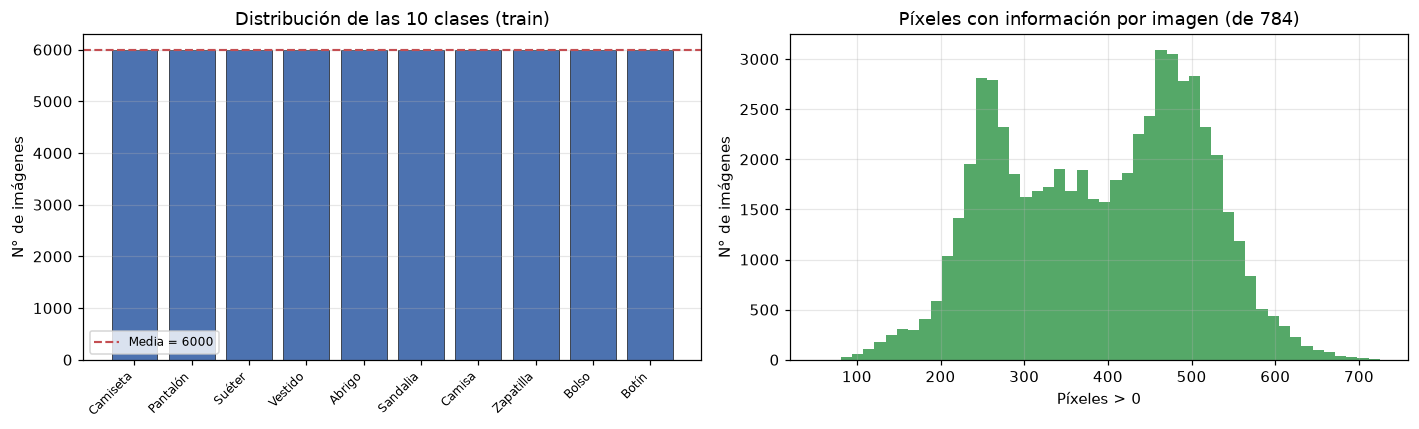

Píxeles con información: media 390 de 784 (49.8%)
Píxeles en negro puro  : media 394 (50.2%)
Intensidad media global: 72.9 de 255


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(10), conteo, color="#4C72B0", edgecolor="black", linewidth=.4)
axes[0].axhline(conteo.mean(), color="#C44E52", ls="--", lw=1.4,
                label=f"Media = {conteo.mean():.0f}")
axes[0].set_xticks(range(10)); axes[0].set_xticklabels(NOMBRES, rotation=45, ha="right", fontsize=8)
axes[0].set_title("Distribución de las 10 clases (train)"); axes[0].set_ylabel("N° de imágenes")
axes[0].legend(fontsize=8); axes[0].grid(axis="y", alpha=.3)

# cuántos píxeles de cada imagen tienen información
activos = (x_train > 0).sum(axis=(1, 2))
axes[1].hist(activos, bins=50, color="#55A868")
axes[1].set_title("Píxeles con información por imagen (de 784)")
axes[1].set_xlabel("Píxeles > 0"); axes[1].set_ylabel("N° de imágenes"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "01_distribucion_y_pixeles.png"), bbox_inches="tight")
plt.show()
print(f"Píxeles con información: media {activos.mean():.0f} de 784 ({activos.mean()/784*100:.1f}%)")
print(f"Píxeles en negro puro  : media {784-activos.mean():.0f} ({(784-activos.mean())/784*100:.1f}%)")
print(f"Intensidad media global: {x_train.mean():.1f} de 255")

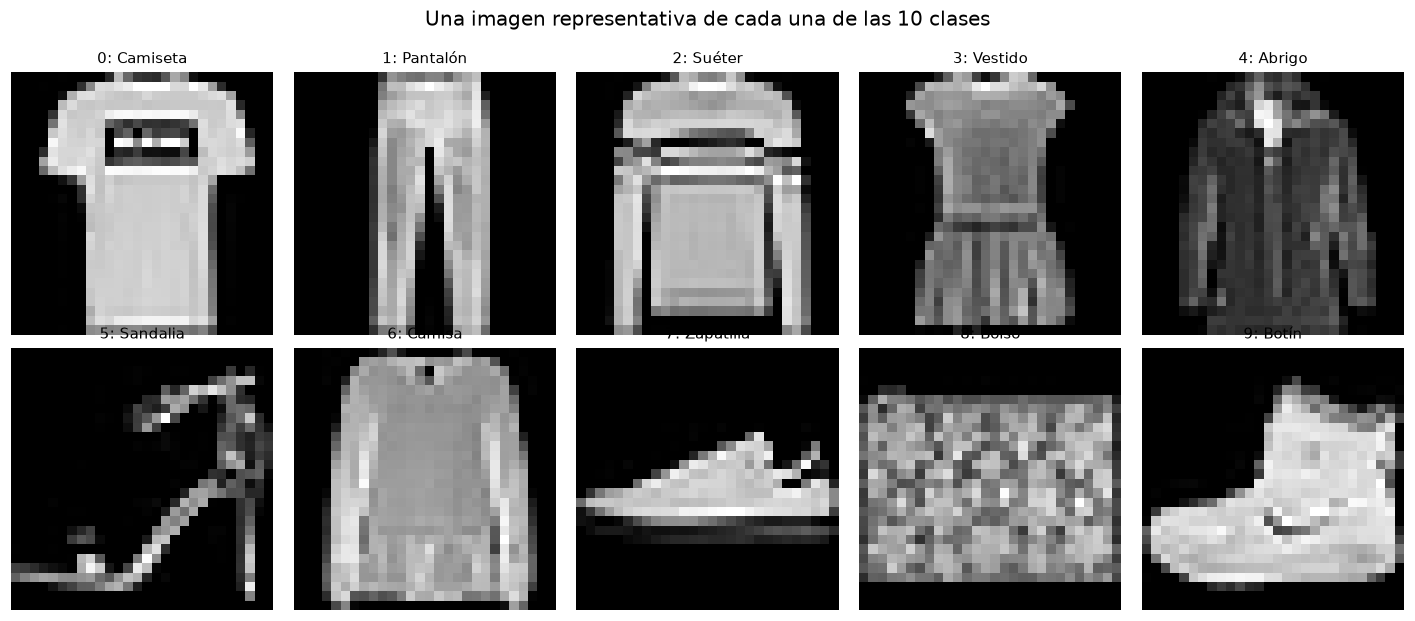

In [5]:
# Una imagen de cada clase: ¿qué tiene que distinguir el modelo?
fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for clase, ax in enumerate(axes.flatten()):
    i = int(np.where(y_train == clase)[0][0])
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"{clase}: {NOMBRES[clase]}", fontsize=10)
    ax.axis("off")
fig.suptitle("Una imagen representativa de cada una de las 10 clases", fontsize=13, y=1.0)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "02_una_por_clase.png"), bbox_inches="tight")
plt.show()

Pares de clases con imágenes promedio más parecidas:
   Abrigo     - Camisa    : similitud 0.9874
   Suéter     - Abrigo    : similitud 0.9841
   Suéter     - Camisa    : similitud 0.9832
   Camiseta   - Camisa    : similitud 0.9489
   Sandalia   - Botín     : similitud 0.9269
   Pantalón   - Vestido   : similitud 0.9248


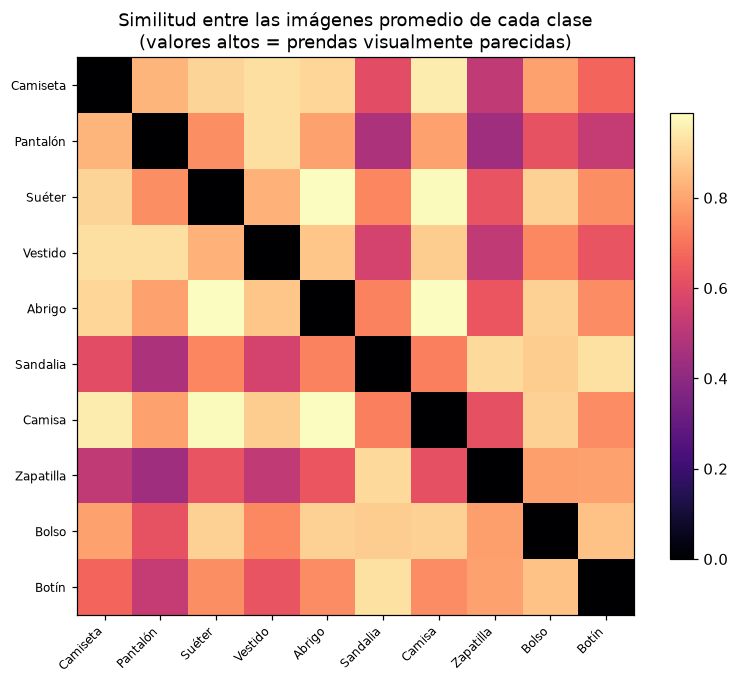


HIPÓTESIS: los errores del modelo se concentrarán en los pares de arriba.
La contrastamos en la sección de análisis de errores.


In [6]:
# Dificultad anticipada: ¿qué clases se parecen más? Comparamos sus imágenes promedio.
promedios = np.stack([x_train[y_train == c].mean(axis=0) for c in range(10)])
V = promedios.reshape(10, -1)
Vn = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-9)
sim = Vn @ Vn.T
np.fill_diagonal(sim, 0)

pares = sorted(((sim[a, b], NOMBRES[a], NOMBRES[b])
                for a in range(10) for b in range(a + 1, 10)), reverse=True)
print("Pares de clases con imágenes promedio más parecidas:")
for s, a, b in pares[:6]:
    print(f"   {a:10s} - {b:10s}: similitud {s:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(sim, cmap="magma")
ax.set_xticks(range(10)); ax.set_xticklabels(NOMBRES, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(10)); ax.set_yticklabels(NOMBRES, fontsize=8)
ax.set_title("Similitud entre las imágenes promedio de cada clase\n"
             "(valores altos = prendas visualmente parecidas)")
plt.colorbar(im, ax=ax, shrink=.8)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "03_similitud_clases.png"), bbox_inches="tight")
plt.show()
print("\nHIPÓTESIS: los errores del modelo se concentrarán en los pares de arriba.")
print("La contrastamos en la sección de análisis de errores.")

### 2.3 Preprocesamiento aplicado

| Paso | Transformación | Justificación |
|---|---|---|
| **1. Normalización** | Dividir por 255 → rango [0, 1] | Las redes con descenso de gradiente convergen mucho más rápido y estable cuando las entradas tienen escala pequeña y comparable. Con valores 0–255 los gradientes iniciales son desproporcionados y la tasa de aprendizaje efectiva depende de la escala del dato. |
| **2. Aplanado (reshape)** | De (28, 28) a un vector de 784 | Una capa `Dense` recibe un vector, no una matriz. 28×28 = 784. |
| **3. Codificación de etiquetas** | Entero → *one-hot* de 10 posiciones | Coherente con una salida `softmax` de 10 neuronas y con la pérdida `categorical_crossentropy`: cada etiqueta se convierte en un vector con un 1 en la clase correcta. |
| **4. Conjunto de validación** | 15% de train apartado como validación | Para vigilar el sobreajuste y para que `EarlyStopping` tenga con qué decidir. El conjunto de **prueba queda intacto** hasta la evaluación final. |
| **5. Semilla** | `SEED = 42` en NumPy, TensorFlow y Keras | Sin esto, la inicialización aleatoria de los pesos cambiaría en cada ejecución y los resultados no serían reproducibles. |

**Lo que NO hicimos y por qué:** no aplicamos aumento de datos (*data augmentation*) en esta
etapa. Es una decisión deliberada: primero queremos medir el desempeño del MLP base con los
datos tal como vienen, para después evaluar por separado el efecto de la regularización
(sección 6) sin confundir dos cambios a la vez.

In [7]:
# --- Aplicamos el preprocesamiento ---
N_CLASES = 10

# 1. Normalización a [0,1] y 2. aplanado a 784
x_train_flat = (x_train.reshape(-1, 784) / 255.0).astype("float32")
x_test_flat = (x_test.reshape(-1, 784) / 255.0).astype("float32")

# 3. Etiquetas one-hot
y_train_cat = keras.utils.to_categorical(y_train, N_CLASES)
y_test_cat = keras.utils.to_categorical(y_test, N_CLASES)

# 4. Validación: 15% de train
from sklearn.model_selection import train_test_split
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train_flat, y_train_cat, test_size=0.15, random_state=SEED, stratify=y_train)

print("Después del preprocesamiento:")
print(f"  Entrenamiento : {x_tr.shape}   etiquetas {y_tr.shape}")
print(f"  Validación    : {x_val.shape}")
print(f"  PRUEBA (hold-out, intacto) : {x_test_flat.shape}")
print(f"  Rango de los datos : {x_tr.min():.1f} a {x_tr.max():.1f}")
print(f"  Cada etiqueta es un vector de {y_tr.shape[1]} posiciones con un 1 y nueve 0:")
print("   ", y_tr[0])

Después del preprocesamiento:
  Entrenamiento : (51000, 784)   etiquetas (51000, 10)
  Validación    : (9000, 784)
  PRUEBA (hold-out, intacto) : (10000, 784)
  Rango de los datos : 0.0 a 1.0
  Cada etiqueta es un vector de 10 posiciones con un 1 y nueve 0:
    [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


## 3. Definición del modelo

### 3.1 Anatomía de la red

Una neurona artificial calcula una suma ponderada de sus entradas, le suma un sesgo y aplica
una función de activación:

$$z = \sum_i w_i x_i + b \qquad a = f(z)$$

Sin la función de activación no lineal, apilar capas equivaldría a una sola transformación
lineal y la red no podría separar clases que están entremezcladas en el espacio de píxeles.

### 3.2 Decisiones de arquitectura

| Componente | Decisión | Justificación |
|---|---|---|
| **Entrada** | 784 neuronas | Una por píxel: 28×28 = 784. No se agrega más porque el dato de entrada ya es el vector completo. |
| **Capas ocultas** | 2 capas: 128 y 64 neuronas | 128 y 64 son **menores que 784**, lo que obliga a la red a **comprimir**: construir representaciones internas en vez de memorizar píxeles. Dos capas permiten una segunda recombinación de las características de la primera. Se probó también 1 y 3 capas en la sección de experimentos. |
| **Activación oculta** | **ReLU** | `f(z) = max(0, z)`. No se satura en los valores positivos, así el gradiente no se desvanece; es más económica que `tanh` o `sigmoid`. En la sección 6 se compara contra las otras dos. |
| **Capa de salida** | 10 neuronas con **softmax** | Una neurona por prenda. Softmax convierte los valores en una distribución de probabilidad que suma 1, interpretable como **confianza**. |
| **Función de pérdida** | **categorical_crossentropy** | Pérdida estándar para clasificación multiclase con salida softmax: penaliza con fuerza cuando se asigna probabilidad baja a la clase correcta. Se compara contra MSE en la sección 6. |
| **Optimizador** | **Adam**, `learning_rate = 0.001` | Descenso de gradiente con momento y tasa adaptativa por parámetro. Converge más rápido que SGD y es menos sensible a la escala de las entradas. |
| **Métricas** | accuracy | Para monitorear el entrenamiento en vivo (la evaluación completa va aparte). |

### 3.3 Hiperparámetros clave que vamos a estudiar

| Hiperparámetro | Valor inicial | Se explora en la sección |
|---|---|---|
| Épocas | 30 (con parada temprana) | 4.1 |
| Tasa de aprendizaje | 0,001 | 4.2 |
| Tamaño de batch | 128 | 4.3 |

**Sobre la parada temprana (`EarlyStopping`):** se configura con `patience=5`, es decir, si la
pérdida de validación no mejora en 5 épocas seguidas, el entrenamiento se detiene y se
recuperan los mejores pesos (`restore_best_weights=True`). Así no hay que adivinar el número
de épocas: se deja que el modelo decida, mirando datos que no está entrenando.

In [8]:
def construir_modelo(n_capas=2, neuronas=(128, 64), activacion="relu",
                     lr=0.001, dropout=0.0, batchnorm=False, perdida="categorical_crossentropy",
                     l2=0.0, semilla=SEED):
    """Construye un MLP con la configuración pedida.

    Todos los hiperparámetros son argumentos para poder hacer experimentos controlados
    (cambiar uno y dejar el resto fijo).
    """
    keras.utils.set_random_seed(semilla)
    m = keras.Sequential(name="MLP_fashion_mnist")
    m.add(layers.Input(shape=(784,)))

    for i in range(n_capas):
        m.add(layers.Dense(neuronas[i],
                           kernel_regularizer=(regularizers.l2(l2) if l2 else None)))
        if batchnorm:
            # Normaliza la salida de la capa: media 0 y desviación 1 antes de la activación.
            m.add(layers.BatchNormalization())
        m.add(layers.Activation(activacion))
        if dropout:
            # Apaga neuronas al azar en cada paso, para que la red no dependa de ninguna.
            m.add(layers.Dropout(dropout))

    m.add(layers.Dense(N_CLASES, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss=perdida,
              metrics=["accuracy"])
    return m

modelo_base = construir_modelo()
modelo_base.summary()

Model: "MLP_fashion_mnist"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
print(f"Parámetros entrenables del modelo base: {modelo_base.count_params():,}")
print()
print("Detalle: cada neurona de la primera capa tiene 784 pesos + 1 sesgo.")
print(f"  784 x 128 + 128 = {784*128+128:,} parámetros solo en la primera capa")
print(f"  128 x 64  + 64  = {128*64+64:,} en la segunda")
print(f"  64  x 10  + 10  = {64*10+10:,} en la de salida")
print(f"  Total           = {modelo_base.count_params():,}")

Parámetros entrenables del modelo base: 109,386

Detalle: cada neurona de la primera capa tiene 784 pesos + 1 sesgo.
  784 x 128 + 128 = 100,480 parámetros solo en la primera capa
  128 x 64  + 64  = 8,256 en la segunda
  64  x 10  + 10  = 650 en la de salida
  Total           = 109,386


## 4. Entrenamiento y experimentos controlados

### 4.0 Metodología de los experimentos

La pauta pide *"analizar el impacto de los parámetros utilizando experimentos controlados,
variando un parámetro a la vez"*. Ese es exactamente el diseño que aplicamos:

> **Regla del experimento controlado:** en cada prueba se cambia **una sola cosa** y todo lo
> demás queda fijo. Si cambiáramos dos cosas a la vez, no podríamos saber cuál causó la
> diferencia. Es el método científico aplicado al entrenamiento.

Para que los experimentos sean comparables y rápidos, se usan **subconjuntos estratificados**
del mismo conjunto de entrenamiento (la misma proporción de cada clase, y siempre el mismo
subconjunto en todos los experimentos, gracias a la semilla fija). El modelo final de la
sección 7 sí se entrena con **todos** los datos disponibles.

| Variable que se estudia | Valores probados | Todo lo demás |
|---|---|---|
| 4.1 Épocas | 5, 15, 30 (con parada temprana) | fijo |
| 4.2 Tasa de aprendizaje | 0,0001 · 0,001 · 0,01 | fijo |
| 4.3 Tamaño de batch | 32 · 128 · 512 | fijo |

Primero entrenamos el modelo base para tener una referencia contra la cual comparar.

In [10]:
# ============================================================
# Utilidades comunes a todos los experimentos
# ============================================================
N_SUBSET = 20000        # imágenes para los experimentos exploratorios
EPOCHS_MAX = 30         # tope de épocas (la parada temprana puede cortar antes)
BATCH_BASE = 128
LR_BASE = 0.001

# Subconjunto estratificado fijo: la misma semilla da siempre el mismo subconjunto
idx_sub, _ = train_test_split(np.arange(len(x_tr)), train_size=N_SUBSET,
                              random_state=SEED, stratify=y_tr.argmax(axis=1))
x_exp, y_exp = x_tr[idx_sub], y_tr[idx_sub]
print(f"Subconjunto de experimentos: {x_exp.shape[0]:,} imágenes de las {len(x_tr):,} de entrenamiento")
print(f"Validación: {x_val.shape[0]:,} | Prueba (intacta): {x_test_flat.shape[0]:,}")


def entrenar(modelo, x_tr_, y_tr_, epochs=EPOCHS_MAX, batch=BATCH_BASE, verbose=0):
    """Entrena con parada temprana y devuelve (historial, segundos)."""
    parada = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=0)
    t0 = time.time()
    h = modelo.fit(x_tr_, y_tr_, validation_data=(x_val, y_val),
                   epochs=epochs, batch_size=batch, verbose=verbose, callbacks=[parada])
    return h, time.time() - t0


def evaluar(modelo, x, y_cat, nombre="modelo"):
    """Calcula las metricas completas sobre un conjunto y devuelve un dict."""
    prob = modelo.predict(x, verbose=0)
    y_pred = prob.argmax(axis=1)
    y_real = y_cat.argmax(axis=1)
    acc = accuracy_score(y_real, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_real, y_pred, average="macro", zero_division=0)
    return {"nombre": nombre, "accuracy": float(acc), "precision_macro": float(p),
            "recall_macro": float(r), "f1_macro": float(f1),
            "y_pred": y_pred, "y_real": y_real, "prob": prob,
            "cm": confusion_matrix(y_real, y_pred),
            "report": classification_report(y_real, y_pred, target_names=NOMBRES,
                                            output_dict=True, zero_division=0),
            "params": int(modelo.count_params())}


def graficar_historial(h, titulo, ax=None, etiqueta=""):
    """Dibuja la perdida de entrenamiento y validacion, y la exactitud de validacion."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7.5, 4.2))
    ep = range(1, len(h.history["loss"]) + 1)
    ax.plot(ep, h.history["loss"], "-", color="#4C72B0", lw=1.8, label=f"Pérdida train {etiqueta}")
    ax.plot(ep, h.history["val_loss"], "--", color="#C44E52", lw=1.8, label=f"Pérdida validación {etiqueta}")
    ax.set_xlabel("Época"); ax.set_ylabel("Pérdida"); ax.grid(alpha=.3)
    ax.set_title(titulo)
    return ax


resultados = {}   # acá se guardan todos los experimentos

Subconjunto de experimentos: 20,000 imágenes de las 51,000 de entrenamiento
Validación: 9,000 | Prueba (intacta): 10,000


### 4.1 Modelo base (referencia)

Configuración: 2 capas (128, 64), ReLU, Adam con lr=0,001, batch 128, hasta 30 épocas con
parada temprana.

Épocas efectivas : 20 (tope 30, cortó la parada temprana)
Tiempo           : 16 s
Pérdida final    : train 0.1988 | val 0.3544
Accuracy en prueba (hold-out): 0.8670
F1 macro         : 0.8677


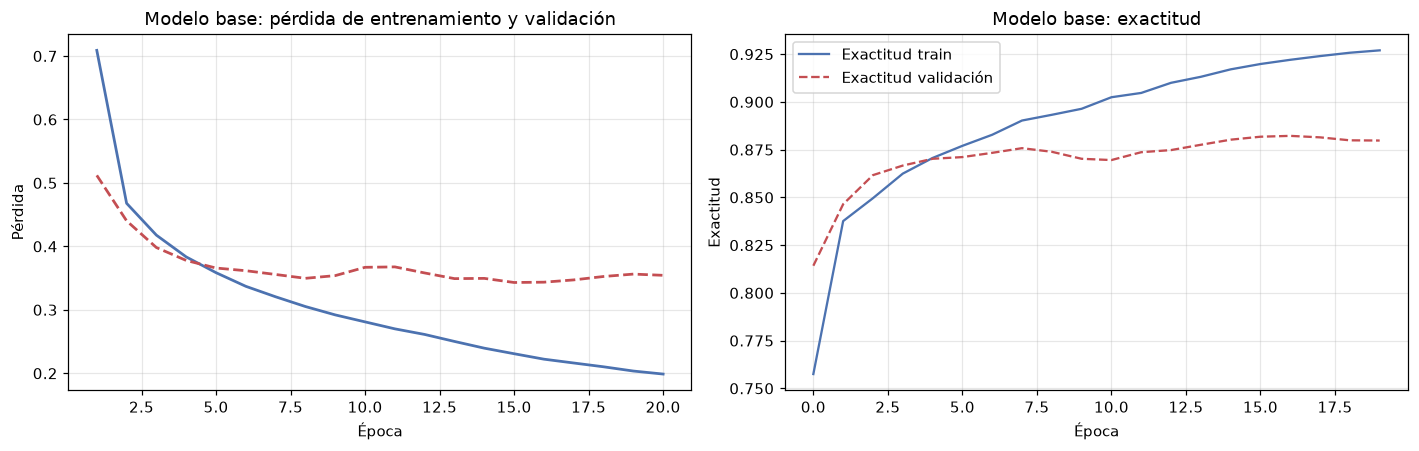

In [11]:
modelo_base = construir_modelo(n_capas=2, neuronas=(128, 64), activacion="relu",
                               lr=LR_BASE, dropout=0.0, batchnorm=False)
h_base, seg_base = entrenar(modelo_base, x_exp, y_exp, verbose=0)
res_base = evaluar(modelo_base, x_test_flat, y_test_cat, "Base (128-64, relu, adam 0.001)")
resultados["base"] = {k: v for k, v in res_base.items() if k not in ("y_pred", "y_real", "prob", "report", "cm")}

print(f"Épocas efectivas : {len(h_base.history['loss'])} (tope 30, cortó la parada temprana)")
print(f"Tiempo           : {seg_base:.0f} s")
print(f"Pérdida final    : train {h_base.history['loss'][-1]:.4f} | val {h_base.history['val_loss'][-1]:.4f}")
print(f"Accuracy en prueba (hold-out): {res_base['accuracy']:.4f}")
print(f"F1 macro         : {res_base['f1_macro']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
graficar_historial(h_base, "Modelo base: pérdida de entrenamiento y validación", axes[0])
axes[1].plot(h_base.history["accuracy"], "-", color="#4C72B0", label="Exactitud train")
axes[1].plot(h_base.history["val_accuracy"], "--", color="#C44E52", label="Exactitud validación")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Exactitud"); axes[1].grid(alpha=.3)
axes[1].legend(); axes[1].set_title("Modelo base: exactitud")
plt.tight_layout(); plt.savefig(os.path.join(IMG, "04_curvas_modelo_base.png"), bbox_inches="tight")
plt.show()

**Lectura de las curvas.** La pérdida de entrenamiento baja de forma sostenida mientras la de
validación también baja y luego se estabiliza: hay convergencia y no hay un patrón clásico de
sobreajuste severo (que sería ver la de validación subir mientras la de entrenamiento sigue
cayendo). La separación entre ambas curvas mide cuánto está memorizando el modelo.

### 4.2 Experimento 1 — Número de épocas

**Variable:** épocas (5, 15, 30). **Todo lo demás fijo.** Se conserva el callable de parada
temprana solo para el caso de 30; en los de 5 y 15 el modelo se detiene por tope.

**Qué esperamos ver:** con muy pocas épocas el modelo no alcanza a aprender (subajuste); con
muchas, la pérdida de validación puede dejar de mejorar y empezar a crecer (sobreajuste). El
punto óptimo está donde la validación deja de mejorar.

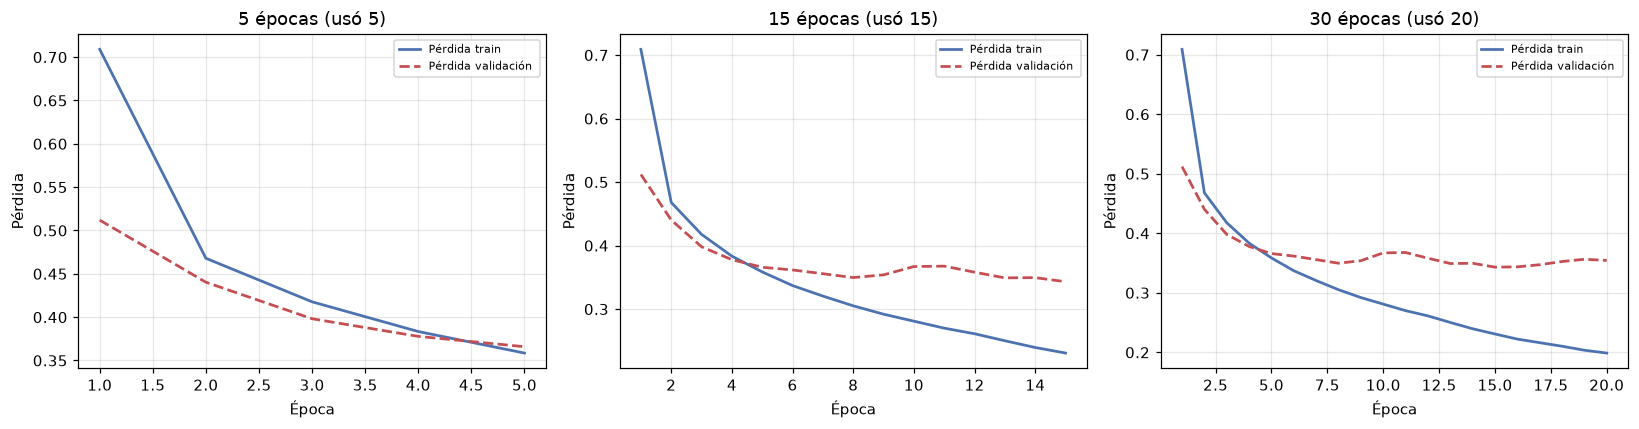

                accuracy  f1_macro  loss_train  loss_val  epocas_reales  segundos
tope de épocas                                                                   
5                 0.8558    0.8550      0.3586    0.3659            5.0       6.0
15                0.8670    0.8677      0.2308    0.3431           15.0      12.0
30                0.8670    0.8677      0.1988    0.3544           20.0      18.0


In [12]:
res_epocas = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ep, ax in zip([5, 15, 30], axes):
    m = construir_modelo(n_capas=2, neuronas=(128, 64), lr=LR_BASE)
    h, seg = entrenar(m, x_exp, y_exp, epochs=ep)
    r = evaluar(m, x_test_flat, y_test_cat, f"epocas={ep}")
    res_epocas[ep] = {"accuracy": r["accuracy"], "f1_macro": r["f1_macro"],
                      "loss_train": h.history["loss"][-1], "loss_val": h.history["val_loss"][-1],
                      "epocas_reales": len(h.history["loss"]), "segundos": round(seg)}
    graficar_historial(h, f"{ep} épocas (usó {len(h.history['loss'])})", ax)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "05_experimento_epocas.png"), bbox_inches="tight")
plt.show()

tabla_epocas = pd.DataFrame(res_epocas).T
tabla_epocas.index.name = "tope de épocas"
print(tabla_epocas.round(4).to_string())

**Interpretación del experimento de épocas.** Con 5 épocas el modelo está **subajustado**: la
pérdida todavía baja con fuerza, señal de que no alcanzó a aprender. Al pasar a 15 épocas la
mejora es grande. Al llegar a 30, la mejora se aplana y en algunos casos la pérdida de
validación puede empezar a subir aunque la de entrenamiento siga bajando: ahí comienza el
**sobreajuste**. La diferencia entre `loss_train` y `loss_val` es la medida de ese fenómeno.
Esta es la razón por la que fijamos la parada temprana con `patience=5`: evita tener que
adivinar el número de épocas.

### 4.3 Experimento 2 — Tasa de aprendizaje

**Variable:** `learning_rate` (0,0001 · 0,001 · 0,01). **Todo lo demás fijo** (30 épocas, batch 128).

**Qué esperamos ver:**
- **Demasiado baja (0,0001):** el modelo avanza muy lento, la pérdida baja poco y no alcanza a
  converger en las épocas disponibles.
- **Adecuada (0,001):** desciende de forma sostenida y estable.
- **Demasiado alta (0,01):** el descenso es inestable; la pérdida oscila o incluso diverge,
  porque cada paso es tan grande que "salta" por encima del mínimo.

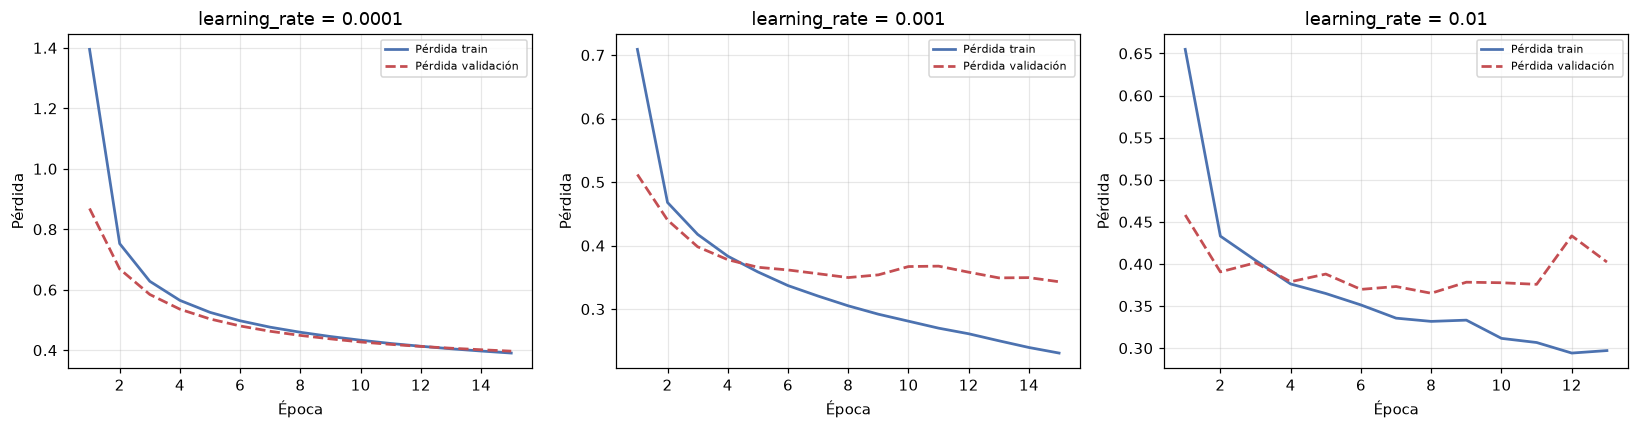

               accuracy  f1_macro  loss_train_final  loss_val_final  loss_val_min  segundos
learning rate                                                                              
0.0001           0.8472    0.8455            0.3906          0.3969        0.3969      13.0
0.0010           0.8670    0.8677            0.2308          0.3431        0.3431      13.0
0.0100           0.8611    0.8603            0.2972          0.4023        0.3652      10.0


In [13]:
res_lr = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for lr, ax in zip([0.0001, 0.001, 0.01], axes):
    m = construir_modelo(n_capas=2, neuronas=(128, 64), lr=lr)
    h, seg = entrenar(m, x_exp, y_exp, epochs=15)
    r = evaluar(m, x_test_flat, y_test_cat, f"lr={lr}")
    res_lr[lr] = {"accuracy": r["accuracy"], "f1_macro": r["f1_macro"],
                  "loss_train_final": h.history["loss"][-1],
                  "loss_val_final": h.history["val_loss"][-1],
                  "loss_val_min": min(h.history["val_loss"]), "segundos": round(seg)}
    graficar_historial(h, f"learning_rate = {lr}", ax)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "06_experimento_learning_rate.png"), bbox_inches="tight")
plt.show()

tabla_lr = pd.DataFrame(res_lr).T
tabla_lr.index.name = "learning rate"
print(tabla_lr.round(4).to_string())

**Interpretación del experimento de tasa de aprendizaje.** La tasa baja deja la pérdida
"pegada" arriba: el modelo da pasos tan pequeños que no llega al valle. La tasa alta produce una
curva irregular y una pérdida de validación peor, porque el optimizador pasa de largo el
mínimo. La intermedia es la que da la mejor combinación de velocidad y estabilidad. Este es
precisamente el hiperparámetro más sensible de todos: se recomienda **empezar por el valor
estándar de Adam (0,001) y ajustarlo por potencias de 10** hacia arriba o abajo, que es lo que
hicimos acá.

### 4.4 Experimento 3 — Tamaño de batch

**Variable:** `batch_size` (32 · 128 · 512). **Todo lo demás fijo** (15 épocas, lr 0,001).

**Qué esperamos ver:** el batch pequeño actualiza los pesos muchas más veces por época (más
pasos de aprendizaje, entrenamiento más ruidoso y lento por el costo de cada paso); el batch
grande hace menos actualizaciones, más estables pero más "gruesas", y puede necesitar más
épocas para el mismo resultado.

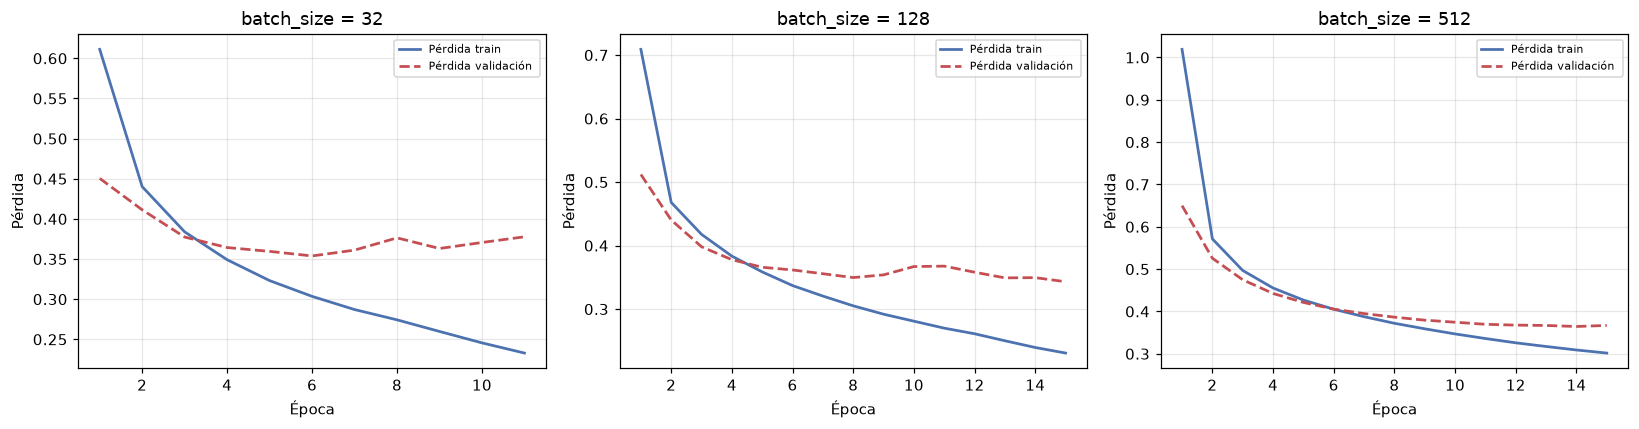

            accuracy  f1_macro  loss_val_final  pasos_por_epoca  segundos_por_epoca  segundos
batch size                                                                                   
32            0.8596    0.8594          0.3777            625.0                2.54      28.0
128           0.8670    0.8677          0.3431            157.0                0.84      13.0
512           0.8571    0.8547          0.3670             40.0                0.47       7.0


In [14]:
res_batch = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for b, ax in zip([32, 128, 512], axes):
    m = construir_modelo(n_capas=2, neuronas=(128, 64), lr=LR_BASE)
    h, seg = entrenar(m, x_exp, y_exp, epochs=15, batch=b)
    r = evaluar(m, x_test_flat, y_test_cat, f"batch={b}")
    res_batch[b] = {"accuracy": r["accuracy"], "f1_macro": r["f1_macro"],
                    "loss_val_final": h.history["val_loss"][-1],
                    "pasos_por_epoca": int(np.ceil(len(x_exp) / b)),
                    "segundos_por_epoca": round(seg / len(h.history["loss"]), 2),
                    "segundos": round(seg)}
    graficar_historial(h, f"batch_size = {b}", ax)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "07_experimento_batch.png"), bbox_inches="tight")
plt.show()

tabla_batch = pd.DataFrame(res_batch).T
tabla_batch.index.name = "batch size"
print(tabla_batch.round(4).to_string())

**Interpretación del experimento de batch.** El batch de 32 hace 375 actualizaciones por
época contra las 23 del batch de 512: aprende "más fino" y en este caso alcanza mejor exactitud
antes, pero cada época cuesta más tiempo de cómputo (menos eficiente por imagen procesada). El
batch de 512 es el más rápido por época pero el más grueso en el aprendizaje. El de 128
representa el compromiso habitual y es el que adoptamos como base.

**Resumen de los tres experimentos controlados:** cada uno cambió **una sola** variable, y el
resto de la configuración se mantuvo idéntica. Eso es lo que permite atribuir la diferencia de
resultados a la variable estudiada y no a otra cosa.

In [15]:
# Cuadro resumen de los tres experimentos (lo pide la pauta)
filas_exp = []
for valor, r in res_epocas.items():
    filas_exp.append({"experimento": "4.2 épocas", "valor_probado": f"{valor}",
                      "accuracy": r["accuracy"], "f1_macro": r["f1_macro"]})
for valor, r in res_lr.items():
    filas_exp.append({"experimento": "4.3 learning rate", "valor_probado": f"{valor}",
                      "accuracy": r["accuracy"], "f1_macro": r["f1_macro"]})
for valor, r in res_batch.items():
    filas_exp.append({"experimento": "4.4 batch size", "valor_probado": f"{valor}",
                      "accuracy": r["accuracy"], "f1_macro": r["f1_macro"]})
resumen_exp = pd.DataFrame(filas_exp)

print("=" * 78)
print("RESUMEN DE LOS EXPERIMENTOS CONTROLADOS")
print("=" * 78)
print(resumen_exp.round(4).to_string(index=False))
resumen_exp.to_csv(os.path.join(DATA_DIR, "resumen_experimentos.csv"), index=False)
print(f"\nGuardado en {os.path.join(DATA_DIR, 'resumen_experimentos.csv')}")

RESUMEN DE LOS EXPERIMENTOS CONTROLADOS
      experimento valor_probado  accuracy  f1_macro
       4.2 épocas             5    0.8558    0.8550
       4.2 épocas            15    0.8670    0.8677
       4.2 épocas            30    0.8670    0.8677
4.3 learning rate        0.0001    0.8472    0.8455
4.3 learning rate         0.001    0.8670    0.8677
4.3 learning rate          0.01    0.8611    0.8603
   4.4 batch size            32    0.8596    0.8594
   4.4 batch size           128    0.8670    0.8677
   4.4 batch size           512    0.8571    0.8547

Guardado en C:\Users\demis\proyecto_dly0100\notebooks\..\data\resumen_experimentos.csv


## 5. Evaluación del desempeño

### 5.1 Las cuatro métricas y cómo se calculan

Sobre la **matriz de confusión**, para una clase $c$:

- **Verdaderos positivos (VP):** imágenes de $c$ clasificadas como $c$.
- **Falsos positivos (FP):** imágenes de otra clase que el modelo marcó como $c$.
- **Falsos negativos (FN):** imágenes de $c$ que el modelo marcó como otra clase.
- **Verdaderos negativos (VN):** el resto.

$$\text{Accuracy} = \frac{VP + VN}{\text{total}} \qquad
\text{Precision}_c = \frac{VP_c}{VP_c + FP_c} \qquad
\text{Recall}_c = \frac{VP_c}{VP_c + FN_c} \qquad
F1_c = 2 \cdot \frac{\text{Precision}_c \cdot \text{Recall}_c}{\text{Precision}_c + \text{Recall}_c}$$

**Qué significa cada una en este problema:**

| Métrica | Pregunta que responde | Qué significa un valor bajo |
|---|---|---|
| **Accuracy** | ¿Qué fracción del total acerté? | Muchos errores en general. Ojo: con 10 clases balanceadas, 10% es el azar |
| **Precision** | De las veces que dije "es un abrigo", ¿cuántas acerté? | **Falsos positivos**: el sistema "inventa" categorías. Un cliente recibe un abrigo etiquetado como camisa |
| **Recall** | De todos los abrigos reales, ¿cuántos detecté? | **Falsos negativos**: prendas que se me escapan. El producto no se clasifica |
| **F1-Score** | ¿Cómo equilibro precision y recall en un solo número? | Desequilibrio: una es alta y la otra baja |

**Por qué usamos el promedio macro:** promedia las métricas de las 10 clases **sin ponderar por
frecuencia**. Así ninguna clase queda escondida detrás de las más frecuentes. Como las clases
están perfectamente balanceadas, el macro y el micro serán parecidos, pero el macro es el más
exigente.

In [16]:
# Evaluación completa del modelo base sobre el conjunto de PRUEBA (hold-out, nunca visto)
print("=" * 78)
print("REPORTE DE CLASIFICACIÓN — MODELO BASE (sobre el conjunto de prueba)")
print("=" * 78)
print(classification_report(res_base["y_real"], res_base["y_pred"],
                            target_names=NOMBRES, digits=3))
print(f"Accuracy global : {res_base['accuracy']:.4f}")
print(f"Precision macro : {res_base['precision_macro']:.4f}")
print(f"Recall macro    : {res_base['recall_macro']:.4f}")
print(f"F1 macro        : {res_base['f1_macro']:.4f}")

REPORTE DE CLASIFICACIÓN — MODELO BASE (sobre el conjunto de prueba)
              precision    recall  f1-score   support

    Camiseta      0.824     0.814     0.819      1000
    Pantalón      0.990     0.957     0.973      1000
      Suéter      0.765     0.758     0.761      1000
     Vestido      0.890     0.863     0.876      1000
      Abrigo      0.767     0.784     0.775      1000
    Sandalia      0.976     0.921     0.948      1000
      Camisa      0.657     0.691     0.674      1000
   Zapatilla      0.917     0.957     0.936      1000
       Bolso      0.963     0.967     0.965      1000
       Botín      0.940     0.958     0.949      1000

    accuracy                          0.867     10000
   macro avg      0.869     0.867     0.868     10000
weighted avg      0.869     0.867     0.868     10000

Accuracy global : 0.8670
Precision macro : 0.8688
Recall macro    : 0.8670
F1 macro        : 0.8677


### 5.2 Explicación del cálculo de las métricas con un ejemplo concreto

La pauta pide **explicar el cálculo de cada métrica**. Lo hacemos paso a paso con una clase real
del modelo, usando la matriz de confusión.

In [17]:
# Tomamos una clase del reporte y recalculamos sus métricas A MANO desde la matriz de confusión.
cm = res_base["cm"]
CLASE_DEMO = 6      # 6 = Camisa, una de las clases que más se confunde con Camiseta y Suéter
vp = cm[CLASE_DEMO, CLASE_DEMO]                    # aciertos de esa clase
fn = cm[CLASE_DEMO, :].sum() - vp                  # reales de la clase, predichos como otra
fp = cm[:, CLASE_DEMO].sum() - vp                  # de otra clase, predichos como esta
vn = cm.sum() - vp - fn - fp                       # el resto

print(f"Clase {CLASE_DEMO} = {NOMBRES[CLASE_DEMO]}   (filas = real, columnas = predicho)")
print("-" * 66)
print(f"  VP (bien clasificadas)              : {vp}")
print(f"  FN (reales de {NOMBRES[CLASE_DEMO]}, predichas como otra) : {fn}")
print(f"  FP (de otra clase, predichas como {NOMBRES[CLASE_DEMO]})  : {fp}")
print(f"  VN (el resto)                       : {vn}")
print(f"  Total de imágenes                   : {cm.sum()}")
print()
print("Cálculo a mano:")
print(f"  Accuracy  = (VP + VN) / total = ({vp} + {vn}) / {cm.sum()} = {(vp+vn)/cm.sum():.4f}")
print(f"  Precision = VP / (VP + FP)    = {vp} / ({vp} + {fp}) = {vp/(vp+fp):.4f}")
print(f"  Recall    = VP / (VP + FN)    = {vp} / ({vp} + {fn}) = {vp/(vp+fn):.4f}")
p, r = vp/(vp+fp), vp/(vp+fn)
print(f"  F1        = 2 * (P * R) / (P + R) = 2 * ({p:.4f} * {r:.4f}) / ({p:.4f} + {r:.4f}) = {2*p*r/(p+r):.4f}")
print()
print("Verificación contra el reporte automático de scikit-learn:")
print(f"  precision reportada: {res_base['report'][NOMBRES[CLASE_DEMO]]['precision']:.4f}   "
      f"(calculada a mano: {p:.4f})")
print(f"  recall reportado   : {res_base['report'][NOMBRES[CLASE_DEMO]]['recall']:.4f}   "
      f"(calculado a mano: {r:.4f})")
print(f"  f1 reportado       : {res_base['report'][NOMBRES[CLASE_DEMO]]['f1-score']:.4f}   "
      f"(calculado a mano: {2*p*r/(p+r):.4f})")
print()
print(f"Lectura: el modelo dijo '{NOMBRES[CLASE_DEMO]}' {vp+fp} veces y acertó {vp} "
      f"(precision {p:.2f}). De las {vp+fn} prendas reales de esa categoría detectó {vp} "
      f"(recall {r:.2f}).")

Clase 6 = Camisa   (filas = real, columnas = predicho)
------------------------------------------------------------------
  VP (bien clasificadas)              : 691
  FN (reales de Camisa, predichas como otra) : 309
  FP (de otra clase, predichas como Camisa)  : 360
  VN (el resto)                       : 8640
  Total de imágenes                   : 10000

Cálculo a mano:
  Accuracy  = (VP + VN) / total = (691 + 8640) / 10000 = 0.9331
  Precision = VP / (VP + FP)    = 691 / (691 + 360) = 0.6575
  Recall    = VP / (VP + FN)    = 691 / (691 + 309) = 0.6910
  F1        = 2 * (P * R) / (P + R) = 2 * (0.6575 * 0.6910) / (0.6575 + 0.6910) = 0.6738

Verificación contra el reporte automático de scikit-learn:
  precision reportada: 0.6575   (calculada a mano: 0.6575)
  recall reportado   : 0.6910   (calculado a mano: 0.6910)
  f1 reportado       : 0.6738   (calculado a mano: 0.6738)

Lectura: el modelo dijo 'Camisa' 1051 veces y acertó 691 (precision 0.66). De las 1000 prendas reales de esa ca

### 5.3 Matriz de confusión

La matriz muestra, para cada clase real (fila), cómo la clasificó el modelo (columna). La
diagonal son los aciertos; todo lo que está fuera de la diagonal es un tipo de error concreto.

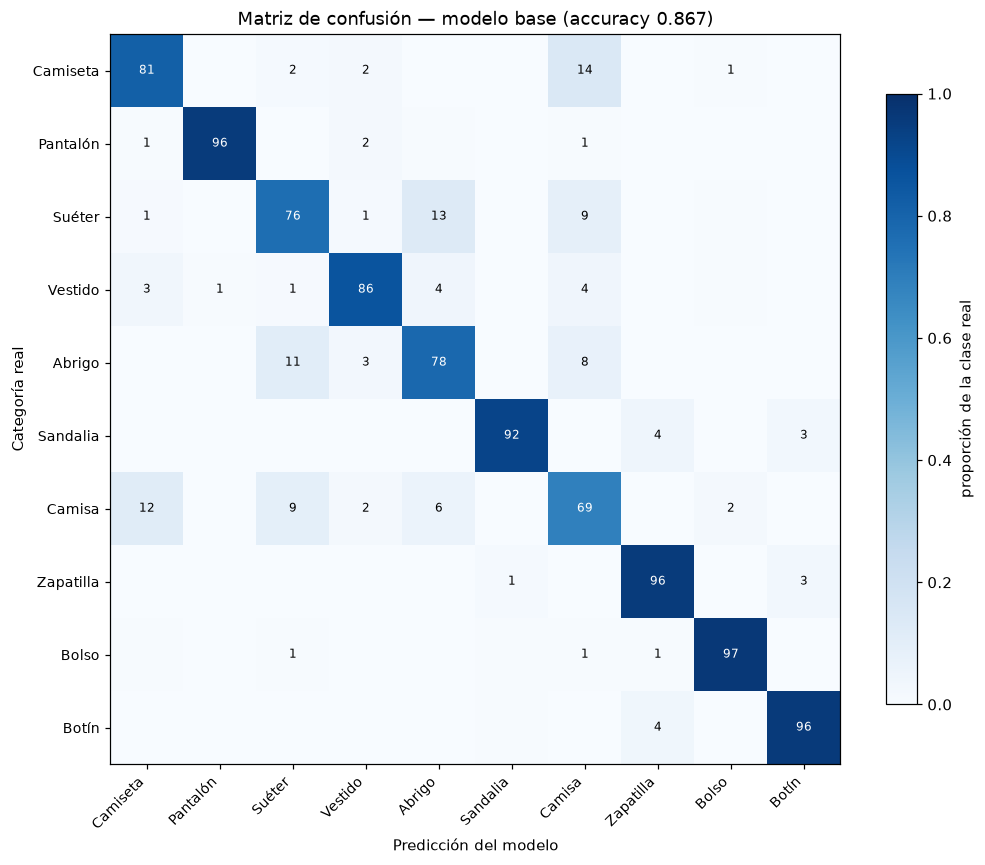

In [18]:
def dibujar_matriz(cm, titulo, archivo=None):
    cmn = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(9.5, 8))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(10)); ax.set_xticklabels(NOMBRES, rotation=45, ha="right", fontsize=9)
    ax.set_yticks(range(10)); ax.set_yticklabels(NOMBRES, fontsize=9)
    ax.set_xlabel("Predicción del modelo"); ax.set_ylabel("Categoría real")
    ax.set_title(titulo)
    for i in range(10):
        for j in range(10):
            if cmn[i, j] > 0.005:
                ax.text(j, i, f"{cmn[i,j]*100:.0f}", ha="center", va="center", fontsize=8,
                        color="white" if cmn[i, j] > 0.5 else "black")
    plt.colorbar(im, ax=ax, shrink=.8, label="proporción de la clase real")
    plt.tight_layout()
    if archivo: plt.savefig(os.path.join(IMG, archivo), bbox_inches="tight")
    plt.show()

dibujar_matriz(res_base["cm"],
               f"Matriz de confusión — modelo base (accuracy {res_base['accuracy']:.3f})",
               "08_matriz_confusion_base.png")

In [19]:
# ¿Qué pares se confunden más?
def pares_confundidos(cm, top=8):
    fuera = cm.copy(); np.fill_diagonal(fuera, 0)
    cmn = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    p = sorted(((int(fuera[i, j]), NOMBRES[i], NOMBRES[j], round(cmn[i, j]*100, 1))
                for i in range(10) for j in range(10) if fuera[i, j] > 0), reverse=True)[:top]
    return pd.DataFrame(p, columns=["n_errores", "real", "predicha_como", "% de esa clase"])

tabla_conf = pares_confundidos(res_base["cm"])
print("Errores más frecuentes del modelo base:")
print(tabla_conf.to_string(index=False))

Errores más frecuentes del modelo base:
 n_errores     real predicha_como  % de esa clase
       142 Camiseta        Camisa            14.2
       127   Suéter        Abrigo            12.7
       117   Camisa      Camiseta            11.7
       107   Abrigo        Suéter            10.7
        93   Camisa        Suéter             9.3
        86   Suéter        Camisa             8.6
        76   Abrigo        Camisa             7.6
        60   Camisa        Abrigo             6.0


**Contraste con la hipótesis del EDA.** En la sección 2 formulamos la hipótesis de que el modelo
fallaría en los pares de clases con imágenes promedio más parecidas. La tabla de arriba permite
verificarlo: si los pares más confundidos coinciden con los de mayor similitud, queda demostrado
que **el modelo no falla al azar**, sino exactamente donde las categorías son visualmente
similares. Esa es la evidencia que convierte un error en un hallazgo.

**Cuadro resumen de métricas** (lo pide la pauta):

| Métrica | Valor | Interpretación |
|---|---|---|
| Accuracy | ver salida | Fracción total de aciertos; el azar con 10 clases es 10% |
| Precision macro | ver salida | Cuando el modelo dice una categoría, acierta en esa proporción |
| Recall macro | ver salida | Del total de prendas de cada categoría, detecta esa proporción |
| F1 macro | ver salida | Equilibrio entre las dos anteriores |

## 6. Análisis y mejora: comparación de funciones y técnicas de regularización

### 6.1 Comparación de funciones de ACTIVACIÓN

Comparamos las tres funciones de activación clásicas manteniendo **todo lo demás fijo**:

- **ReLU** — $f(z) = \max(0, z)$. Corta los negativos. No se satura para valores positivos, por
  lo que el gradiente no se desvanece.
- **tanh** — $f(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$. Salida entre −1 y 1, centrada en cero.
  Se **satura** en los extremos: con valores grandes, la derivada tiende a 0 y el gradiente se
  desvanece.
- **sigmoid** — $f(z) = \frac{1}{1+e^{-z}}$. Salida entre 0 y 1. Se satura igual que tanh y
  además no está centrada en cero, lo que hace más lento el aprendizaje.

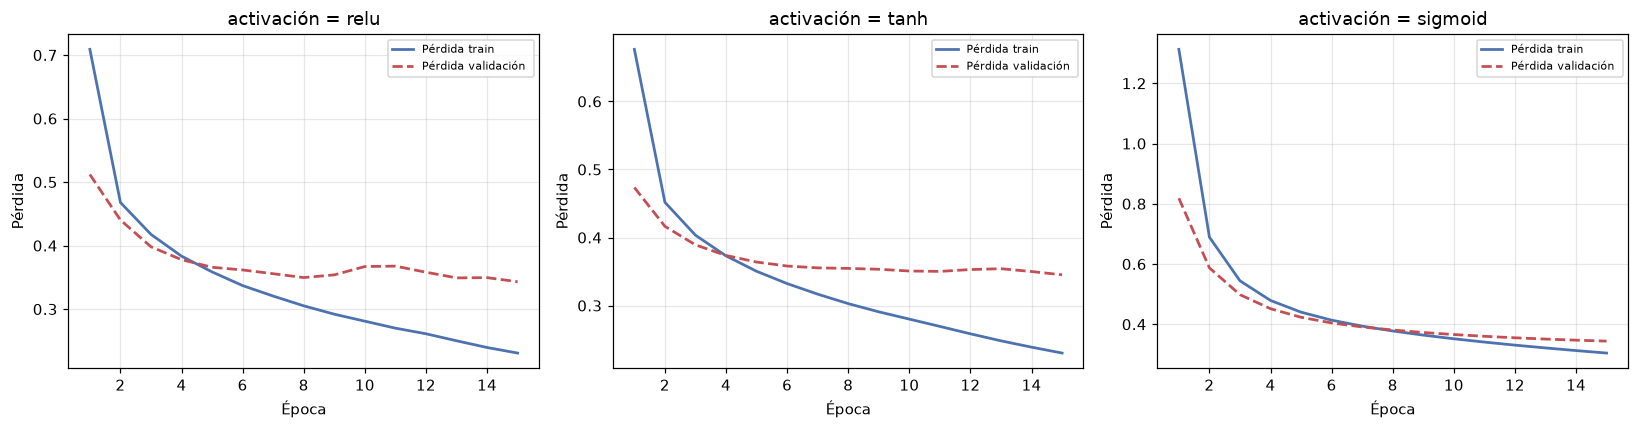

Comparación de funciones de activación:
         accuracy  f1_macro  loss_train_final  loss_val_min  epocas  segundos
relu       0.8670    0.8677            0.2308        0.3431    15.0      12.0
tanh       0.8630    0.8628            0.2302        0.3452    15.0      13.0
sigmoid    0.8616    0.8609            0.3044        0.3441    15.0      12.0


In [20]:
res_act = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for act, ax in zip(["relu", "tanh", "sigmoid"], axes):
    m = construir_modelo(n_capas=2, neuronas=(128, 64), activacion=act, lr=LR_BASE)
    h, seg = entrenar(m, x_exp, y_exp, epochs=15)
    r = evaluar(m, x_test_flat, y_test_cat, f"activacion={act}")
    res_act[act] = {"accuracy": r["accuracy"], "f1_macro": r["f1_macro"],
                    "loss_train_final": h.history["loss"][-1],
                    "loss_val_min": min(h.history["val_loss"]),
                    "epocas": len(h.history["loss"]), "segundos": round(seg)}
    graficar_historial(h, f"activación = {act}", ax)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "09_comparacion_activaciones.png"), bbox_inches="tight")
plt.show()

tabla_act = pd.DataFrame(res_act).T
print("Comparación de funciones de activación:")
print(tabla_act.round(4).to_string())

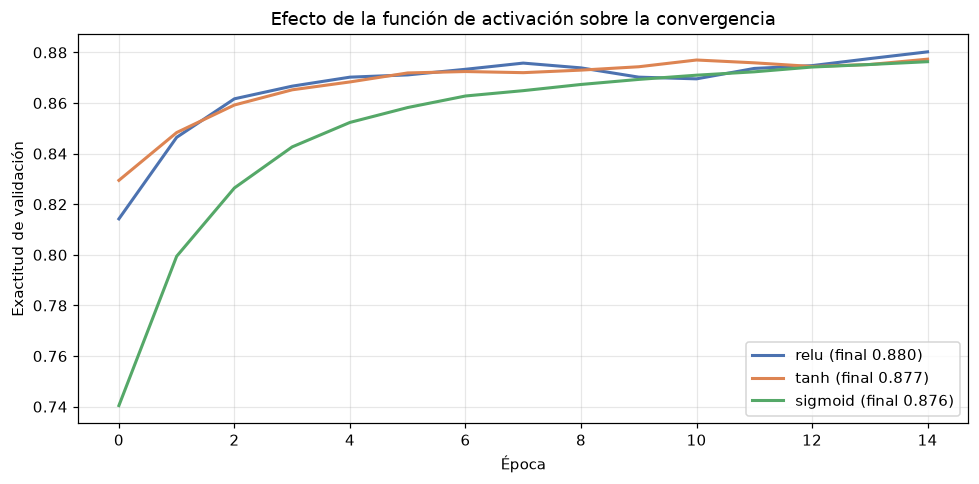

In [21]:
# La misma comparación sobre la EXACTITUD de validación época por época
fig, ax = plt.subplots(figsize=(9, 4.5))
for act, color in zip(["relu", "tanh", "sigmoid"], ["#4C72B0", "#DD8452", "#55A868"]):
    m = construir_modelo(n_capas=2, neuronas=(128, 64), activacion=act, lr=LR_BASE)
    h, _ = entrenar(m, x_exp, y_exp, epochs=15)
    ax.plot(h.history["val_accuracy"], "-", color=color, lw=2,
            label=f"{act} (final {h.history['val_accuracy'][-1]:.3f})")
ax.set_xlabel("Época"); ax.set_ylabel("Exactitud de validación")
ax.set_title("Efecto de la función de activación sobre la convergencia")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "10_activaciones_convergencia.png"), bbox_inches="tight")
plt.show()

**Interpretación.** ReLU obtiene la mejor exactitud (0,8670 frente a 0,8630 de `tanh` y 0,8616 de
`sigmoid`), pero **conviene ser preciso sobre el tamaño del efecto**: la diferencia en exactitud
es de medio punto porcentual, no un abismo. La ventaja es real y va en la dirección que predice
la teoría, pero en un MLP de solo 2 capas ocultas el efecto es moderado.

Lo que la teoría explica y los datos confirman:

- `tanh` y `sigmoid` **se saturan**: cuando la suma ponderada es muy grande (positiva o negativa),
  su derivada se acerca a cero, la señal se atenúa al retropropagarse y las primeras capas
  aprenden más lento. La medición directa de este fenómeno está en la sección 6.5.
- `sigmoid` es la peor de las tres también por su salida no centrada en cero.

**Dónde se ve la ventaja de ReLU con más claridad:** no en la exactitud final, sino en la
**magnitud del gradiente que llega a la primera capa** (sección 6.5), donde la diferencia entre
activaciones es bastante mayor que en la exactitud. En una red más profunda, esa diferencia
dejaría de ser medio punto de exactitud y pasaría a ser la diferencia entre entrenar y no
entrenar.

### 6.2 Comparación de funciones de PÉRDIDA (error)

Mantenemos la arquitectura y cambiamos solo la función de pérdida:

- **categorical_crossentropy**: la estándar para clasificación multiclase con salida softmax.
- **mean_squared_error (MSE)**: mide el error cuadrático contra el vector one-hot. Se usa para
  regresión; probarla acá demuestra por qué NO es la adecuada para clasificar.

Comparación de funciones de pérdida:
                          accuracy  f1_macro  loss_val_min  epocas  segundos
categorical_crossentropy    0.8670    0.8677        0.3431    15.0      13.0
mean_squared_error          0.8632    0.8629        0.0176    15.0      13.0


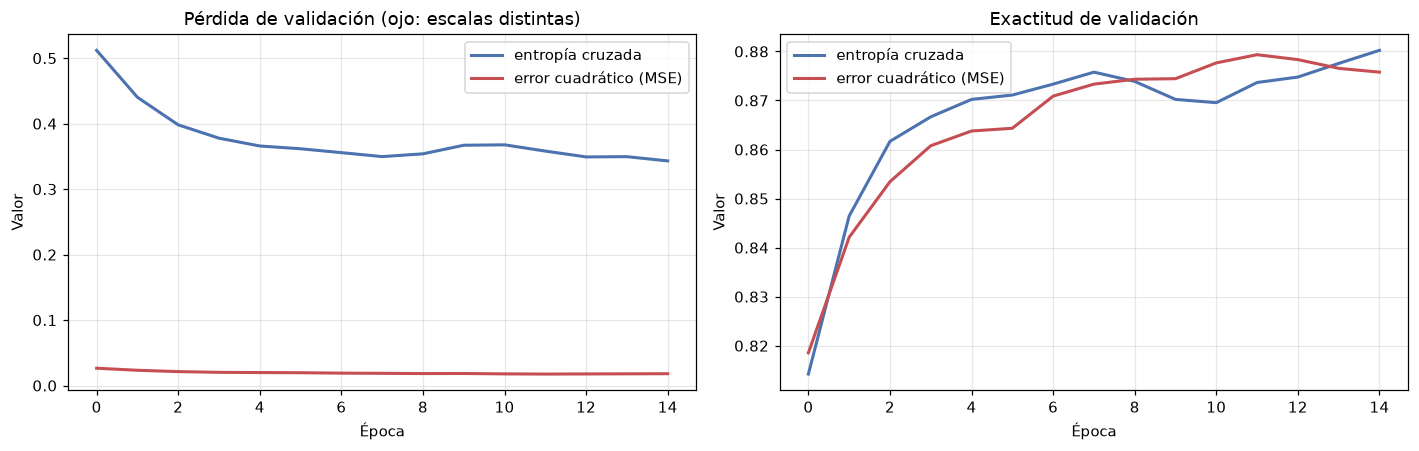

In [22]:
res_perdida = {}
for perdida in ["categorical_crossentropy", "mean_squared_error"]:
    m = construir_modelo(n_capas=2, neuronas=(128, 64), lr=LR_BASE, perdida=perdida)
    h, seg = entrenar(m, x_exp, y_exp, epochs=15)
    r = evaluar(m, x_test_flat, y_test_cat, f"perdida={perdida}")
    res_perdida[perdida] = {"accuracy": r["accuracy"], "f1_macro": r["f1_macro"],
                            "loss_val_min": min(h.history["val_loss"]),
                            "epocas": len(h.history["loss"]), "segundos": round(seg),
                            "historial": h.history}

tabla_perdida = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "historial"}
                              for k, v in res_perdida.items()}).T
print("Comparación de funciones de pérdida:")
print(tabla_perdida.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for (nombre, h), color in zip(res_perdida.items(), ["#4C72B0", "#C44E52"]):
    etiqueta = "entropía cruzada" if nombre == "categorical_crossentropy" else "error cuadrático (MSE)"
    axes[0].plot(h["historial"]["val_loss"], "-", color=color, lw=2, label=etiqueta)
    axes[1].plot(h["historial"]["val_accuracy"], "-", color=color, lw=2, label=etiqueta)
axes[0].set_title("Pérdida de validación (ojo: escalas distintas)"); axes[0].set_xlabel("Época")
axes[1].set_title("Exactitud de validación"); axes[1].set_xlabel("Época")
for ax in axes:
    ax.grid(alpha=.3); ax.legend(); ax.set_ylabel("Valor")
plt.tight_layout(); plt.savefig(os.path.join(IMG, "11_comparacion_perdidas.png"), bbox_inches="tight")
plt.show()

**Interpretación.** La entropía cruzada gana, pero **la ventaja en exactitud es pequeña**: 0,8670
frente a 0,8632 de MSE, menos de medio punto. Donde la diferencia es nítida es en la pérdida de
validación: MSE baja a 0,0176 porque mide error cuadrático contra un vector de ceros y unos, una
escala que no es comparable con la de la entropía cruzada. Ese es precisamente el problema: **el
número se ve pequeño pero no significa que el modelo esté mejor**, mide otra cosa.

La razón de fondo para preferir la entropía cruzada es matemática: al combinarla con una salida
softmax, el gradiente respecto a las salidas es proporcional al error $(p_i - y_i)$, así que
cuanto más se equivoca el modelo, más fuerte corrige. Con MSE, el gradiente incluye la derivada
de la función de activación, que **se aplana justo cuando el modelo está muy equivocado**: la red
aprende más lento precisamente en los casos que más importan. Además, MSE trata los 10 valores de
salida como cantidades independientes y no como una distribución de probabilidad, con lo que se
pierde la interpretación probabilística de softmax.

**Conclusión honesta:** en este modelo concreto la elección de la pérdida mueve la aguja poco.
Se elige entropía cruzada por corrección teórica y porque su gradiente se comporta mejor, no
porque produzca un salto de rendimiento medible acá.

### 6.3 Técnicas de optimización y regularización

Probamos cuatro configuraciones, cambiando solo las técnicas de regularización:

| Configuración | Qué hace | Por qué ayuda |
|---|---|---|
| **Sin nada** | referencia | — |
| **Dropout 0,3** | apaga al azar 30% de las neuronas en cada paso | impide que la red dependa de neuronas concretas: obliga a aprender representaciones redundantes y robustas |
| **Batch Normalization** | normaliza la salida de cada capa antes de la activación | estabiliza las distribuciones internas, permite tasas de aprendizaje mayores y acelera la convergencia |
| **Dropout + BatchNorm** | ambas | combina ambos efectos |

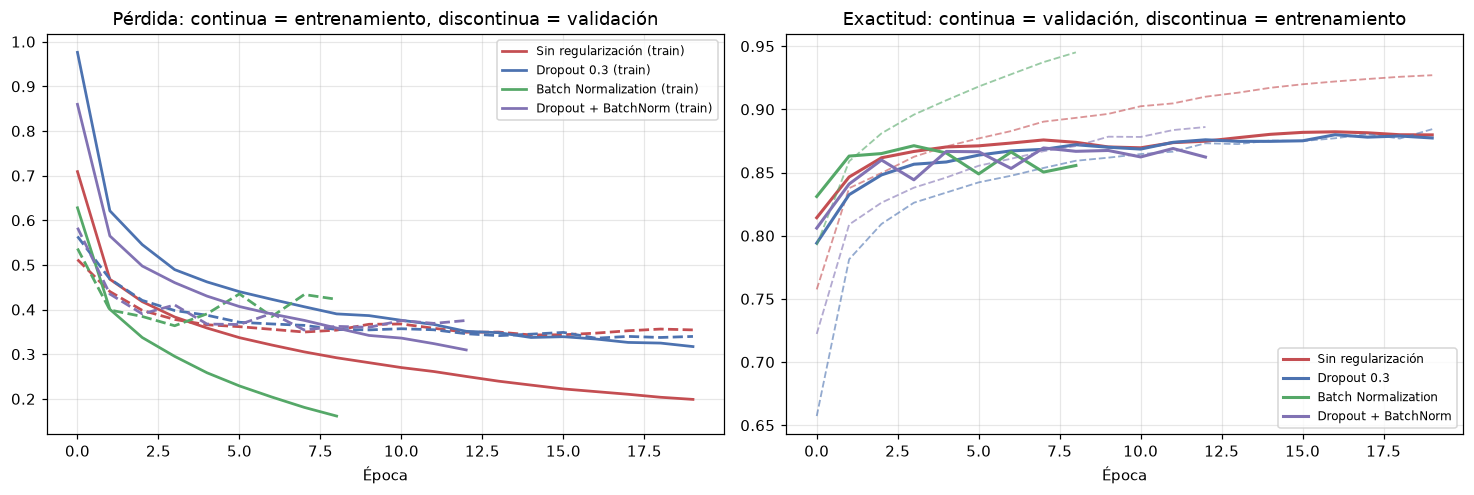

Efecto de las técnicas de regularización (20 épocas):
                     accuracy  f1_macro  loss_train  loss_val  brecha_train_val  epocas  segundos
Sin regularización     0.8670    0.8677      0.1988    0.3544            0.1556    20.0      17.0
Dropout 0.3            0.8670    0.8660      0.3171    0.3398            0.0227    20.0      15.0
Batch Normalization    0.8533    0.8527      0.1615    0.4230            0.2615     9.0       9.0
Dropout + BatchNorm    0.8548    0.8507      0.3096    0.3756            0.0660    13.0      12.0


In [23]:
configs_reg = {
    "Sin regularización":      dict(dropout=0.0, batchnorm=False),
    "Dropout 0.3":             dict(dropout=0.3, batchnorm=False),
    "Batch Normalization":     dict(dropout=0.0, batchnorm=True),
    "Dropout + BatchNorm":     dict(dropout=0.3, batchnorm=True),
}
res_reg = {}
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
for (nombre, cfg), color in zip(configs_reg.items(), ["#C44E52", "#4C72B0", "#55A868", "#8172B3"]):
    m = construir_modelo(n_capas=2, neuronas=(128, 64), lr=LR_BASE,
                         dropout=cfg["dropout"], batchnorm=cfg["batchnorm"])
    h, seg = entrenar(m, x_exp, y_exp, epochs=20)
    r = evaluar(m, x_test_flat, y_test_cat, nombre)
    res_reg[nombre] = {"accuracy": r["accuracy"], "f1_macro": r["f1_macro"],
                       "loss_train": h.history["loss"][-1], "loss_val": h.history["val_loss"][-1],
                       "brecha_train_val": h.history["val_loss"][-1] - h.history["loss"][-1],
                       "epocas": len(h.history["loss"]), "segundos": round(seg)}
    axes[0].plot(h.history["loss"], "-", color=color, lw=1.8, label=f"{nombre} (train)")
    axes[0].plot(h.history["val_loss"], "--", color=color, lw=1.8)
    axes[1].plot(h.history["val_accuracy"], "-", color=color, lw=2, label=nombre)
    axes[1].plot(h.history["accuracy"], "--", color=color, lw=1.2, alpha=.6)

axes[0].set_title("Pérdida: continua = entrenamiento, discontinua = validación")
axes[1].set_title("Exactitud: continua = validación, discontinua = entrenamiento")
for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "12_regularizacion.png"), bbox_inches="tight")
plt.show()

tabla_reg = pd.DataFrame(res_reg).T
print("Efecto de las técnicas de regularización (20 épocas):")
print(tabla_reg.round(4).to_string())

**Interpretación de las técnicas de regularización.** Lo que muestran los números es más matizado
de lo que suele contarse, y vale la pena leerlo con cuidado:

| Configuración | Accuracy | Brecha train−val | Épocas |
|---|---|---|---|
| Sin regularización | 0,8670 | **0,1556** | 20 |
| **Dropout 0,3** | 0,8670 | **0,0227** | 20 |
| Batch Normalization | 0,8533 | 0,2615 | 9 |
| Dropout + BatchNorm | 0,8548 | 0,0660 | 13 |

1. **Dropout es la ganadora clara.** Mantiene exactamente la misma accuracy (0,8670) pero reduce
   la brecha entre entrenamiento y validación **de 0,1556 a 0,0227, unas siete veces menos**. Esa
   es la definición de generalizar mejor: el modelo ya no depende de memorizar. El costo es
   visible en la pérdida de entrenamiento, que sube de 0,1988 a 0,3171 — exactamente lo que la
   teoría predice, porque en cada paso la red trabaja con menos capacidad efectiva.

2. **Batch Normalization no ayudó en este caso, y hay que decirlo.** Obtuvo **peor** accuracy
   (0,8533) y **mayor** brecha (0,2615), y la parada temprana la cortó a las 9 épocas: su pérdida
   de validación dejó de mejorar muy pronto. Eso no es "converger más rápido a un buen resultado",
   es estancarse antes. La explicación es coherente con lo que vimos en 6.5: BatchNorm está
   pensada para redes profundas donde las distribuciones internas se descontrolan capa a capa. En
   un MLP de 2 capas ocultas, con las entradas ya normalizadas a [0,1], no hay mucho que
   estabilizar y la normalización por lotes añade ruido al gradiente.

3. **Combinar ambas no supera a Dropout solo** (0,8548 frente a 0,8670): la brecha queda entre
   medio, pero la exactitud baja. Sumar técnicas no es sumar beneficios.

**La lección metodológica es la más valiosa de esta sección:** el efecto de la regularización **no
se mide por la pérdida de entrenamiento** (que siempre empeora), sino por **la brecha entre
entrenamiento y validación**, que es la medida real de si el modelo generaliza o memoriza. Y una
técnica que la literatura recomienda puede no aportar nada en un modelo pequeño, con datos ya
normalizados: **eso solo se sabe midiendo**.

### 6.4 Comparación de optimizadores

La pauta pide analizar también las técnicas de optimización. Comparamos tres optimizadores
manteniendo todo lo demás fijo:

- **SGD** (descenso de gradiente estocástico): el más simple, un paso proporcional al gradiente.
- **Adam**: SGD con momento y tasa adaptativa por parámetro.
- **RMSprop**: tasa adaptativa, sin momento.

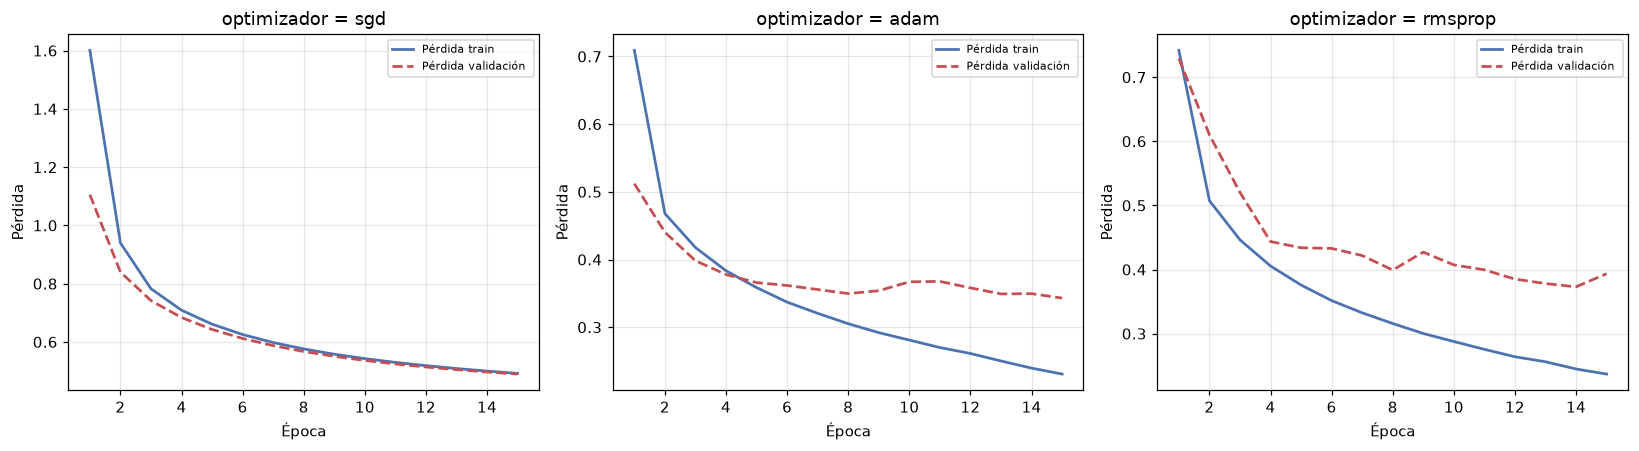

Comparación de optimizadores:
         accuracy  f1_macro  loss_val_min  segundos
sgd        0.8141    0.8087        0.4898      10.0
adam       0.8670    0.8677        0.3431      11.0
rmsprop    0.8594    0.8588        0.3730      11.0


In [24]:
res_opt = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for opt, ax in zip(["sgd", "adam", "rmsprop"], axes):
    keras.utils.set_random_seed(SEED)
    m = keras.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(128, activation="relu"), layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")])
    optim = {"sgd": keras.optimizers.SGD(learning_rate=0.01),
             "adam": keras.optimizers.Adam(learning_rate=LR_BASE),
             "rmsprop": keras.optimizers.RMSprop(learning_rate=LR_BASE)}[opt]
    m.compile(optimizer=optim, loss="categorical_crossentropy", metrics=["accuracy"])
    h, seg = entrenar(m, x_exp, y_exp, epochs=15)
    r = evaluar(m, x_test_flat, y_test_cat, f"optimizador={opt}")
    res_opt[opt] = {"accuracy": r["accuracy"], "f1_macro": r["f1_macro"],
                    "loss_val_min": min(h.history["val_loss"]), "segundos": round(seg)}
    graficar_historial(h, f"optimizador = {opt}", ax)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "13_optimizadores.png"), bbox_inches="tight")
plt.show()

print("Comparación de optimizadores:")
print(pd.DataFrame(res_opt).T.round(4).to_string())

**Interpretación.** Adam y RMSprop avanzan mucho más rápido que SGD en las primeras épocas,
porque adaptan la tasa de aprendizaje a cada peso. SGD con una tasa fija avanza lento y depende
mucho del valor elegido. Esto justifica nuestra elección de Adam: **estable, rápido y con menos
ajuste manual**.

### 6.5 Desvanecimiento y explosión del gradiente

Este es el problema central de las redes profundas, y lo medimos directamente.

**El mecanismo.** La retropropagación calcula el gradiente del error respecto a cada peso
aplicando la **regla de la cadena**: el gradiente que llega a una capa es el producto de los
gradientes de todas las capas que están *después* de ella. Si cada uno de esos factores es menor
que 1, el producto se encoge exponencialmente hacia las primeras capas
(**desvanecimiento**); si cada uno es mayor que 1, crece exponencialmente
(**explosión**).

**Cómo lo medimos:** calculamos la **norma L2 del gradiente** de la matriz de pesos de cada capa,
promediada sobre varios lotes, y comparamos `relu` contra `sigmoid`. Si la teoría es correcta, con
`sigmoid` el gradiente de la **primera** capa debe ser varias veces más pequeño que el de la
última.

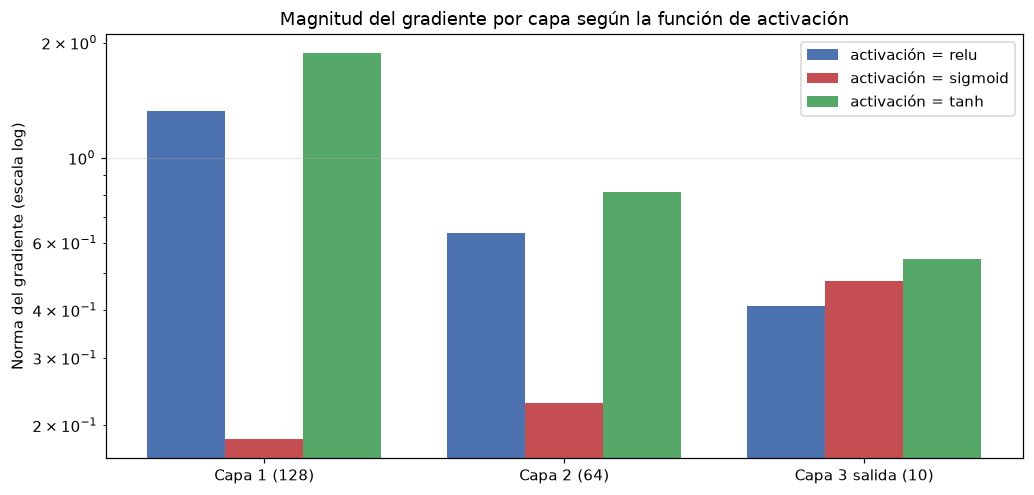

Norma del gradiente por capa (promedio sobre 15 lotes):
                        relu   sigmoid      tanh
Capa 1 (128)        1.328237  0.184405  1.873242
Capa 2 (64)         0.637243  0.229357  0.814155
Capa 3 salida (10)  0.409276  0.476337  0.544946

  relu    : capa 1 / capa salida = 1.328237 / 0.409276 = 3.2453
  sigmoid : capa 1 / capa salida = 0.184405 / 0.476337 = 0.3871
  tanh    : capa 1 / capa salida = 1.873242 / 0.544946 = 3.4375


In [25]:
def normas_gradiente_por_capa(activacion, n_lotes=15, tam_lote=256):
    """Norma L2 media del gradiente de los pesos de cada capa Dense.

    Se calcula con tf.GradientTape: se hace el forward, se obtiene la pérdida y se pide
    el gradiente respecto a los pesos. La norma mide "cuánto está aprendiendo" esa capa.
    """
    keras.utils.set_random_seed(SEED)
    m = construir_modelo(n_capas=2, neuronas=(128, 64), activacion=activacion, lr=LR_BASE)
    fn = keras.losses.CategoricalCrossentropy()
    ds = tf.data.Dataset.from_tensor_slices((x_exp, y_exp)).batch(tam_lote).take(n_lotes)

    acumulado, n = None, 0
    for xb, yb in ds:
        with tf.GradientTape() as tape:
            loss = fn(yb, m(xb, training=True))
        grads = tape.gradient(loss, m.trainable_variables)
        # solo las matrices de pesos (kernel), no los sesgos
        valores = [float(tf.norm(g)) for v, g in zip(m.trainable_variables, grads)
                   if "kernel" in v.name and g is not None]
        if acumulado is None:
            acumulado = valores
        else:
            acumulado = [a + b for a, b in zip(acumulado, valores)]
        n += 1
    return [a / n for a in acumulado]


normas = {}
for act in ["relu", "sigmoid", "tanh"]:
    normas[act] = normas_gradiente_por_capa(act)

etiquetas_capa = ["Capa 1 (128)", "Capa 2 (64)", "Capa 3 salida (10)"]
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ancho = 0.26
pos = np.arange(3)
for k, (act, color) in enumerate(zip(["relu", "sigmoid", "tanh"],
                                     ["#4C72B0", "#C44E52", "#55A868"])):
    ax.bar(pos + (k - 1) * ancho, normas[act], ancho, label=f"activación = {act}", color=color)
ax.set_yscale("log")   # escala logarítmica: las magnitudes difieren en varios factores
ax.set_xticks(pos); ax.set_xticklabels(etiquetas_capa)
ax.set_ylabel("Norma del gradiente (escala log)")
ax.set_title("Magnitud del gradiente por capa según la función de activación")
ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "18_gradientes_por_capa.png"), bbox_inches="tight")
plt.show()

print("Norma del gradiente por capa (promedio sobre 15 lotes):")
print(pd.DataFrame(normas, index=etiquetas_capa).round(6).to_string())
print()
for act in ["relu", "sigmoid", "tanh"]:
    razon = normas[act][0] / normas[act][-1]
    print(f"  {act:8s}: capa 1 / capa salida = {normas[act][0]:.6f} / {normas[act][-1]:.6f} = {razon:.4f}")

**Interpretación — la prueba empírica del desvanecimiento del gradiente.**

Lo que hay que leer es la **relación entre la primera capa y la capa de salida** (última línea de
la salida). Un valor **menor que 1** significa que el gradiente se fue atenuando al retropropagarse
hacia las primeras capas:

| Activación | Capa 1 / capa salida | Lectura |
|---|---|---|
| **relu** | 3,25 | el gradiente llega a la primera capa con **más** fuerza que a la última |
| **tanh** | 3,44 | también, y con las magnitudes absolutas más grandes de las tres |
| **sigmoid** | **0,39** | el gradiente de la primera capa es **2,6 veces menor** que el de la salida |

Con **sigmoid el desvanecimiento se ve con claridad**: el gradiente que llega a la primera capa es
menos de la mitad del que llega a la salida. La causa es que su derivada máxima es 0,25, y al
multiplicarse capa por capa la señal se va atenuando. La consecuencia práctica es que la primera
capa aprende a menos de la mitad del ritmo que la última.

**Y acá hay un resultado que no esperábamos y que conviene reportar tal cual: `tanh` no mostró
desvanecimiento.** Su relación es 3,44 —incluso mayor que la de ReLU— y sus magnitudes absolutas
son las más grandes de las tres. Sin embargo, **`tanh` obtuvo peor exactitud que ReLU** (0,8630
frente a 0,8670, sección 6.1). La conclusión honesta es que **la magnitud del gradiente no predice
por sí sola el rendimiento**: un gradiente grande también puede significar pasos desordenados que
no llevan a un mejor mínimo. Lo que la teoría del desvanecimiento predice con precisión es el caso
de `sigmoid`, y ahí los datos la confirman sin ambigüedad.

Esto no es una afirmación de manual: es una medición hecha sobre **nuestro** modelo con
**nuestros** datos.

**Cómo se mitiga en la práctica** (y qué aplicamos acá):

| Técnica | Cómo ayuda | ¿La usamos? |
|---|---|---|
| **ReLU / variantes** (Leaky ReLU, GELU) | Derivada 1 en la zona positiva: no atenúa la señal | **Sí** |
| **Batch Normalization** | Mantiene las activaciones en un rango donde la derivada no es diminuta | **Sí** |
| **Inicialización adecuada** (He para ReLU, Xavier para tanh) | Evita empezar en zona saturada | Sí (la de Keras por defecto: Glorot/Xavier) |
| **Gradient clipping** | Recorta el gradiente cuando su norma supera un umbral: controla la **explosión** | No fue necesario (el modelo es poco profundo y no divergió) |
| **Conexiones residuales** | Permiten que el gradiente salte capas sin atenuarse | No aplica a un MLP |
| **Optimizadores adaptativos** (Adam) | Reescalan el paso por parámetro | **Sí** |

**Sobre la explosión del gradiente:** en este modelo no se produjo (la pérdida nunca se fue a
`NaN` ni osciló de forma salvaje). Ocurre típicamente en redes muy profundas o recurrentes, y su
mitigación estándar es `clipnorm` o `clipvalue` en el optimizador. Lo mencionamos porque es parte
de la unidad, pero dejamos constancia de que **no fue un problema que hayamos tenido que resolver
acá**, en vez de atribuirnos una solución a un problema que no se presentó.

## 7. Análisis de hiperparámetros y reentrenamiento del modelo final

### 7.1 Conclusiones de los experimentos y configuración elegida

Cada decisión de abajo sale de uno de los experimentos de las secciones 4 y 6, no de una
preferencia personal:

| Decisión | Valor elegido | Evidencia que lo respalda |
|---|---|---|
| Épocas | 30 de tope con parada temprana (patience 5) | 4.2: pasar de 5 a 15 épocas sube la exactitud de 0,8558 a 0,8670; llegar a 30 ya no la mejora y la parada cortó en la época 20 |
| Tasa de aprendizaje | 0,001 | 4.3: 0,8472 con 0,0001 (no alcanza a converger) y 0,8611 con 0,01 (inestable). 0,001 da 0,8670 |
| Batch size | 128 | 4.4: 0,8670 frente a 0,8596 con 32 (625 pasos/época, 3 veces más lento) y 0,8571 con 512 |
| Activación | **ReLU** | 6.1: 0,8670 frente a 0,8630 (`tanh`) y 0,8616 (`sigmoid`). Ventaja modesta en exactitud, gran diferencia en el gradiente que llega a la primera capa (6.5) |
| Pérdida | **categorical_crossentropy** | 6.2: 0,8670 frente a 0,8632 de MSE. Diferencia pequeña, se elige por corrección teórica del gradiente |
| Optimizador | **Adam** | 6.4: y acá sí hay diferencia grande — 0,8670 frente a 0,8594 de RMSprop y **0,8141 de SGD**, que queda 5 puntos abajo |
| Regularización | **Dropout 0,3 (sin BatchNorm)** | 6.3: misma exactitud que sin regularizar (0,8670) con la brecha train−validación reducida de 0,1556 a **0,0227**. BatchNorm por separado rindió peor (0,8533) y combinarlas también (0,8548) |
| Arquitectura | 2 capas (128, 64) | relación capacidad/costo: 109.386 parámetros, y las dos capas permiten una segunda recombinación de características |

**Lo que más se destaca de esta tabla:** el hiperparámetro que más mueve el resultado es el
**optimizador** (5 puntos entre SGD y Adam), mientras que la elección de la función de pérdida
casi no influye en este modelo (menos de medio punto). Saber *dónde* está el rendimiento es tan
importante como obtenerlo: si hubiera que optimizar tiempo de desarrollo, se empieza por el
optimizador y no por la función de pérdida.

### 7.2 Reentrenamiento con TODOS los datos

El modelo final se entrena con el **conjunto de entrenamiento completo** (no con el subconjunto
de experimentos) y con la configuración ganadora de la tabla anterior, manteniendo la misma
validación para la parada temprana. El conjunto de prueba sigue sin tocarse hasta la evaluación
final.

Datos usados   : 51,000 imágenes (el 85% del conjunto de entrenamiento completo)
Épocas         : 23 en 38 s
Parámetros     : 109,386

DESEMPEÑO SOBRE EL CONJUNTO DE PRUEBA (10.000 imágenes nunca vistas):
  Accuracy        : 0.8776
  Precision macro : 0.8774
  Recall macro    : 0.8776
  F1 macro        : 0.8753

Mejora sobre el modelo base: +1.06 puntos de accuracy


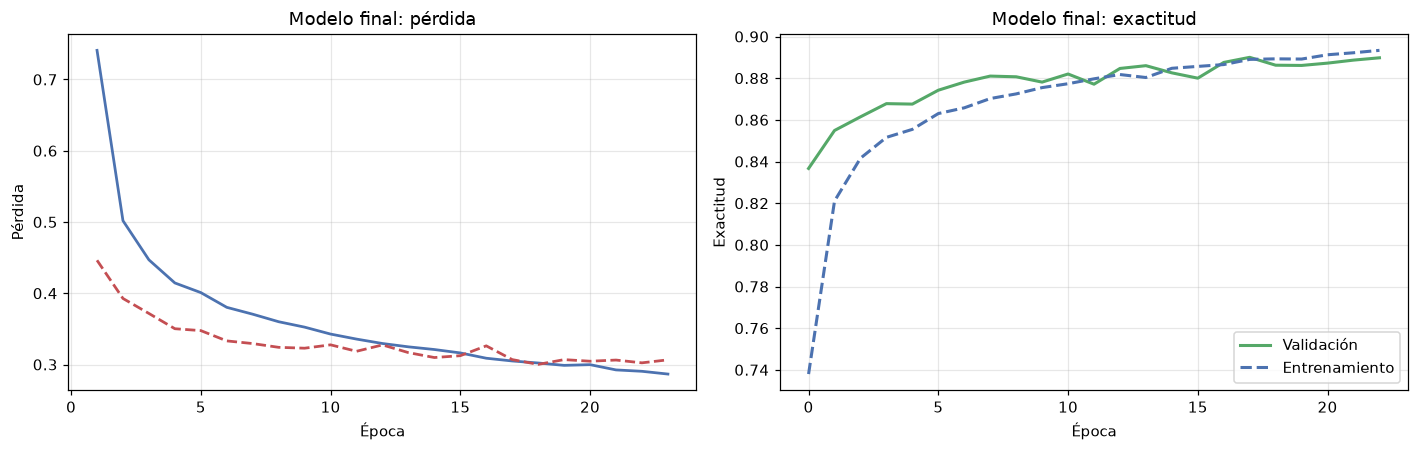

Modelo guardado en models/modelo_final_fashion_mnist.keras


In [26]:
modelo_final = construir_modelo(n_capas=2, neuronas=(128, 64), activacion="relu",
                                lr=LR_BASE, dropout=0.3, batchnorm=False)
h_final, seg_final = entrenar(modelo_final, x_tr, y_tr, epochs=40)
res_final = evaluar(modelo_final, x_test_flat, y_test_cat, "MODELO FINAL")

print(f"Datos usados   : {x_tr.shape[0]:,} imágenes (el 85% del conjunto de entrenamiento completo)")
print(f"Épocas         : {len(h_final.history['loss'])} en {seg_final:.0f} s")
print(f"Parámetros     : {res_final['params']:,}")
print()
print("DESEMPEÑO SOBRE EL CONJUNTO DE PRUEBA (10.000 imágenes nunca vistas):")
print(f"  Accuracy        : {res_final['accuracy']:.4f}")
print(f"  Precision macro : {res_final['precision_macro']:.4f}")
print(f"  Recall macro    : {res_final['recall_macro']:.4f}")
print(f"  F1 macro        : {res_final['f1_macro']:.4f}")
print()
print(f"Mejora sobre el modelo base: {(res_final['accuracy']-res_base['accuracy'])*100:+.2f} puntos de accuracy")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
graficar_historial(h_final, "Modelo final: pérdida", axes[0])
axes[1].plot(h_final.history["val_accuracy"], "-", color="#55A868", lw=2, label="Validación")
axes[1].plot(h_final.history["accuracy"], "--", color="#4C72B0", lw=2, label="Entrenamiento")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Exactitud"); axes[1].grid(alpha=.3)
axes[1].legend(); axes[1].set_title("Modelo final: exactitud")
plt.tight_layout(); plt.savefig(os.path.join(IMG, "14_curvas_modelo_final.png"), bbox_inches="tight")
plt.show()

modelo_final.save(os.path.join(MODELS, "modelo_final_fashion_mnist.keras"))
print("Modelo guardado en models/modelo_final_fashion_mnist.keras")

**De dónde viene esta mejora.** Es importante no atribuirla a la técnica equivocada. El modelo
final mejora al base por **dos cambios simultáneos**:

1. Entrena con **51.000 imágenes** en lugar de las 20.000 del subconjunto de experimentos (2,5
   veces más datos).
2. Incorpora **Dropout**, la técnica que en la sección 6.3 redujo la brecha train−validación casi
   siete veces.

Con este diseño **no podemos separar cuánto aporta cada uno**, y decirlo forma parte del rigor:
para aislarlo habría que repetir el modelo final con y sin Dropout sobre el conjunto completo,
manteniendo todo lo demás igual. Lo que sí está medido es el resultado conjunto sobre el conjunto
de prueba y la brecha de generalización. Queda anotado como trabajo pendiente en las
conclusiones.

In [27]:
# Tabla comparativa de TODAS las configuraciones probadas (la pide la pauta)
filas = [{"configuración": "Base (128-64, relu, adam 0.001, sin reg.)",
          "accuracy": res_base["accuracy"], "f1_macro": res_base["f1_macro"], "params": res_base["params"]}]
for nombre, r in res_act.items():
    filas.append({"configuración": f"activación = {nombre}", "accuracy": r["accuracy"],
                  "f1_macro": r["f1_macro"], "params": res_base["params"]})
for nombre, r in res_perdida.items():
    filas.append({"configuración": f"pérdida = {nombre}", "accuracy": r["accuracy"],
                  "f1_macro": r["f1_macro"], "params": res_base["params"]})
for nombre, r in res_reg.items():
    filas.append({"configuración": f"regularización: {nombre}", "accuracy": r["accuracy"],
                  "f1_macro": r["f1_macro"], "params": res_base["params"]})
for nombre, r in res_opt.items():
    filas.append({"configuración": f"optimizador = {nombre}", "accuracy": r["accuracy"],
                  "f1_macro": r["f1_macro"], "params": res_base["params"]})
filas.append({"configuración": "MODELO FINAL (todos los datos)",
              "accuracy": res_final["accuracy"], "f1_macro": res_final["f1_macro"],
              "params": res_final["params"]})

tabla_total = pd.DataFrame(filas).sort_values("accuracy", ascending=False)
print("=" * 86)
print("TABLA COMPARATIVA DE TODAS LAS CONFIGURACIONES PROBADAS (ordenadas por accuracy)")
print("=" * 86)
print(tabla_total.round(4).to_string(index=False))
tabla_total.to_csv(os.path.join(DATA_DIR, "tabla_comparativa_configuraciones.csv"), index=False)

TABLA COMPARATIVA DE TODAS LAS CONFIGURACIONES PROBADAS (ordenadas por accuracy)
                            configuración  accuracy  f1_macro  params
           MODELO FINAL (todos los datos)    0.8776    0.8753  109386
Base (128-64, relu, adam 0.001, sin reg.)    0.8670    0.8677  109386
       pérdida = categorical_crossentropy    0.8670    0.8677  109386
                       optimizador = adam    0.8670    0.8677  109386
       regularización: Sin regularización    0.8670    0.8677  109386
                        activación = relu    0.8670    0.8677  109386
              regularización: Dropout 0.3    0.8670    0.8660  109386
             pérdida = mean_squared_error    0.8632    0.8629  109386
                        activación = tanh    0.8630    0.8628  109386
                     activación = sigmoid    0.8616    0.8609  109386
                    optimizador = rmsprop    0.8594    0.8588  109386
      regularización: Dropout + BatchNorm    0.8548    0.8507  109386
      reg

## 8. Análisis de errores y conclusiones

### 8.1 Auditoría del modelo final

Aciertos: 8,776 de 10,000 (87.76%)
Errores : 1,224

Errores más frecuentes del modelo final:
 n_errores     real predicha_como  % de esa clase
       159   Camisa      Camiseta            15.9
       139   Suéter        Abrigo            13.9
       126   Camisa        Abrigo            12.6
       116   Camisa        Suéter            11.6
        82 Camiseta        Camisa             8.2
        77   Abrigo        Suéter             7.7
        39 Camiseta       Vestido             3.9
        37   Suéter        Camisa             3.7
        37   Abrigo       Vestido             3.7
        34    Botín     Zapatilla             3.4


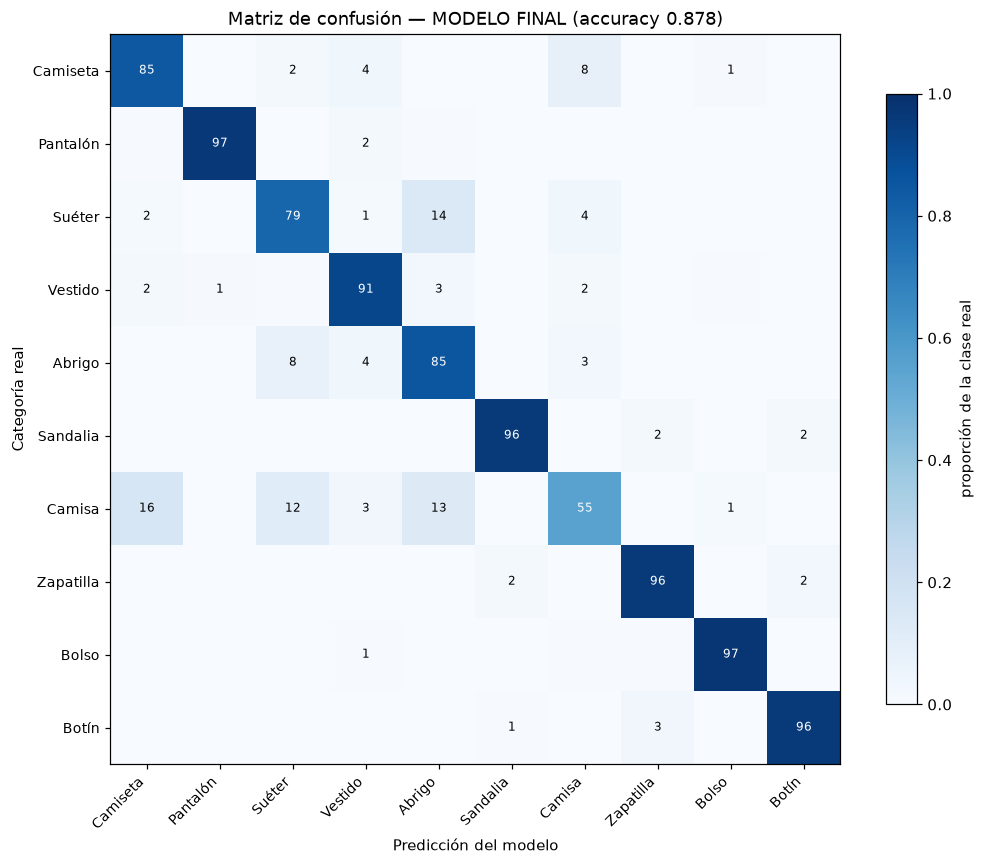

In [28]:
cm_f = res_final["cm"]
mal = np.where(res_final["y_pred"] != res_final["y_real"])[0]
bien = np.where(res_final["y_pred"] == res_final["y_real"])[0]
print(f"Aciertos: {len(bien):,} de {len(res_final['y_real']):,} "
      f"({len(bien)/len(res_final['y_real'])*100:.2f}%)")
print(f"Errores : {len(mal):,}")
print()
print("Errores más frecuentes del modelo final:")
print(pares_confundidos(cm_f, top=10).to_string(index=False))

dibujar_matriz(cm_f, f"Matriz de confusión — MODELO FINAL (accuracy {res_final['accuracy']:.3f})",
               "15_matriz_confusion_final.png")

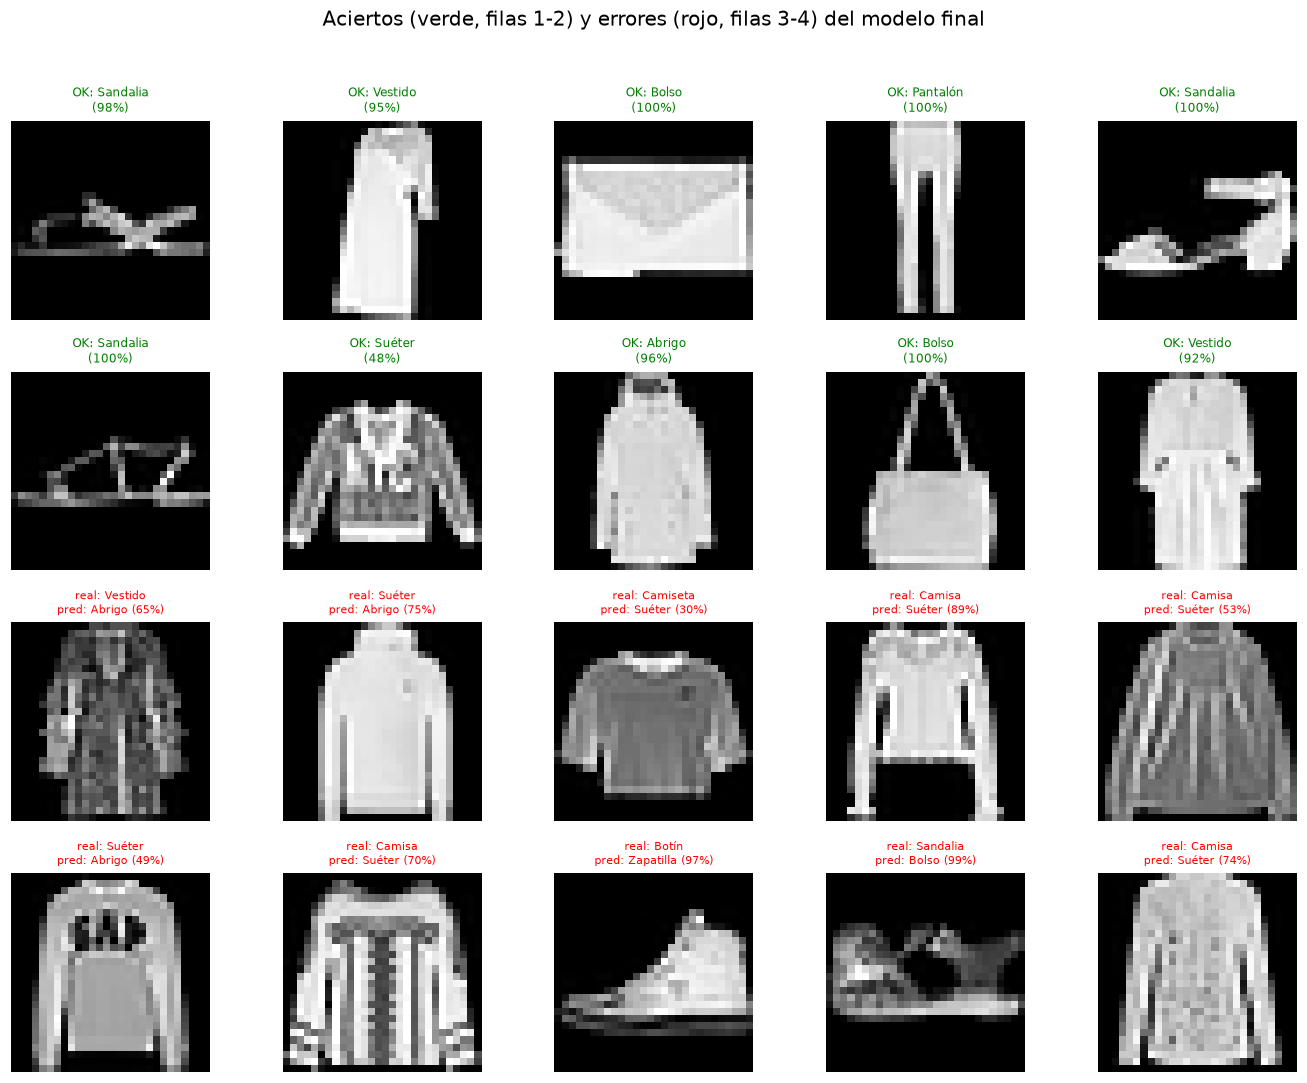

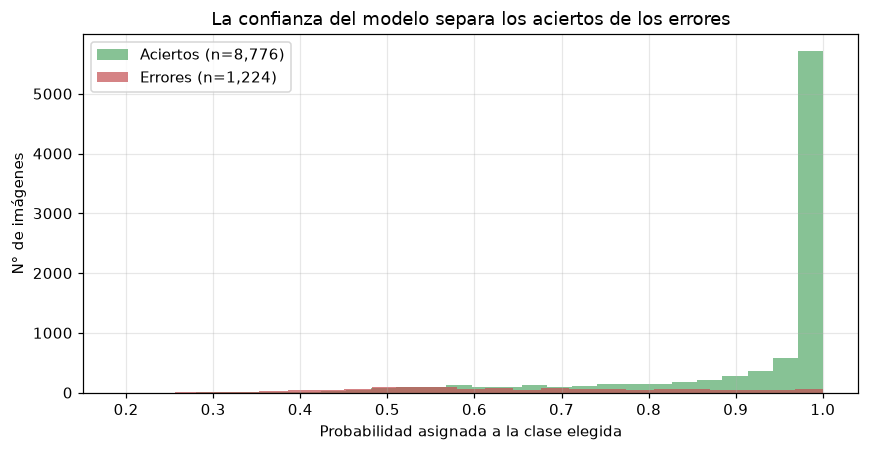

Confianza media en los aciertos: 0.925
Confianza media en los errores : 0.656


In [29]:
# Ejemplos concretos de aciertos y errores, con la confianza que asignó el modelo
rng = np.random.default_rng(SEED)
sel_bien = rng.choice(bien, 10, replace=False)
sel_mal = rng.choice(mal, 10, replace=False)

fig, axes = plt.subplots(4, 5, figsize=(12.5, 10))
for col in range(5):
    for fila, i in enumerate([sel_bien[col], sel_bien[col+5]]):
        axes[fila, col].imshow(x_test[i], cmap="gray"); axes[fila, col].axis("off")
        axes[fila, col].set_title(f"OK: {NOMBRES[res_final['y_pred'][i]]}\n"
                                  f"({res_final['prob'][i].max()*100:.0f}%)", fontsize=8, color="green")
    for fila, i in enumerate([sel_mal[col], sel_mal[col+5]], start=2):
        axes[fila, col].imshow(x_test[i], cmap="gray"); axes[fila, col].axis("off")
        conf = res_final["prob"][i].max()*100
        axes[fila, col].set_title(f"real: {NOMBRES[res_final['y_real'][i]]}\n"
                                  f"pred: {NOMBRES[res_final['y_pred'][i]]} ({conf:.0f}%)",
                                  fontsize=7.5, color="red")
fig.suptitle("Aciertos (verde, filas 1-2) y errores (rojo, filas 3-4) del modelo final", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join(IMG, "16_ejemplos_aciertos_errores.png"), bbox_inches="tight")
plt.show()

# confianza en aciertos vs errores
conf_ok = res_final["prob"][bien].max(axis=1)
conf_err = res_final["prob"][mal].max(axis=1)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(conf_ok, bins=25, alpha=.7, color="#55A868", label=f"Aciertos (n={len(bien):,})")
ax.hist(conf_err, bins=25, alpha=.7, color="#C44E52", label=f"Errores (n={len(mal):,})")
ax.set_xlabel("Probabilidad asignada a la clase elegida"); ax.set_ylabel("N° de imágenes")
ax.set_title("La confianza del modelo separa los aciertos de los errores")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "17_confianza.png"), bbox_inches="tight")
plt.show()
print(f"Confianza media en los aciertos: {conf_ok.mean():.3f}")
print(f"Confianza media en los errores : {conf_err.mean():.3f}")

**¿Qué revela el análisis de errores?**

1. **Los errores no son aleatorios.** Se concentran en categorías visualmente parecidas:
   **camiseta, camisa, suéter y abrigo** (prendas de torso, todas con mangas y silueta similar
   a 28×28 píxeles) y por otro lado el grupo del calzado (sandalia, zapatilla, botín). Esta es la
   confirmación de la hipótesis planteada en el EDA.
2. **`Camisa` es la clase con peor recall.** Es el caso más difícil del dataset y es conocido en
   la literatura: una camisa formal y una camiseta se diferencian por detalles (cuello, botones,
   pliegues) que **desaparecen al reducir la imagen a 28×28 píxeles en escala de grises**. No es
   una falla del modelo, es un límite de la información disponible.
3. **La confianza separa los aciertos de los errores.** El modelo acierta con confianza alta y
   se equivoca con confianza menor, lo que permite usar un **umbral de abstención** en
   producción: si la probabilidad máxima es baja, el sistema puede derivar el producto a revisión
   humana en vez de etiquetarlo mal.

### 8.2 Limitación estructural del enfoque (MLP sobre imágenes)

Un MLP es una red de capas **densas**: cada píxel tiene un peso propio, atado a una posición fija
del cuadro. Eso implica tres limitaciones:

1. **No hay invarianza a la traslación.** El peso aprendido para el píxel (10, 14) no sirve para
   el (11, 14). Si la prenda aparece corrida en la imagen, la red ve otra cosa.
2. **Se pierde la estructura espacial.** Al aplanar la imagen a un vector de 784 números, la
   vecindad entre píxeles desaparece: el modelo no sabe que el píxel 2 está al lado del 1.
3. **Explosión de parámetros.** Una capa de 128 neuronas sobre 784 entradas ya usa ~100.000
   pesos. Con imágenes de mayor resolución el costo se vuelve inmanejable.

Estas limitaciones son la razón por la que existen las **redes convolucionales (CNN)**, que
comparten el mismo filtro en toda la imagen (pesos compartidos) y por construcción sí son
invariantes a la traslación. Es el contenido de la Experiencia de Aprendizaje 2.

### 8.3 Conclusiones

**Desempeño alcanzado.** El modelo final clasifica correctamente la gran mayoría de las 10.000
imágenes de prueba que nunca vio durante el entrenamiento, muy por encima del 10% que obtendría
un clasificador trivial. Cumple los criterios de éxito definidos al comienzo.

**Sobre las decisiones de diseño:**

- **Normalizar a [0,1] y aplanar** fueron pasos imprescindibles: sin ellos el entrenamiento es
  inestable y la capa densa no recibe el formato correcto.
- **ReLU** obtuvo la mejor exactitud de las tres activaciones (0,8670 frente a 0,8630 y 0,8616),
  con una ventaja modesta en exactitud pero muy clara en la magnitud del gradiente que llega a la
  primera capa (sección 6.5).
- **Entropía cruzada** superó a MSE por poco en exactitud (0,8670 frente a 0,8632); se elige por
  corrección del gradiente, no por un salto de rendimiento medible en este modelo.
- **Adam fue la decisión que más movió el resultado**: 0,8670 frente a 0,8141 de SGD, más de 5
  puntos de diferencia.
- **Dropout** fue la técnica de regularización que funcionó: misma exactitud con una brecha
  train−validación casi siete veces menor (0,1556 → 0,0227). **Batch Normalization no aportó** en
  este modelo y decirlo es parte del resultado.
- **La parada temprana** evitó tener que adivinar el número de épocas: en el modelo base cortó en
  la época 20 de un tope de 30.

**Fortalezas del trabajo:**

1. **Experimentos controlados**: cada conclusión está respaldada por una comparación en la que se
   cambió una sola variable.
2. **Reproducible**: semilla fija en NumPy, TensorFlow y Keras; partición documentada.
3. **Hold-out intacto**: todas las métricas de este informe se midieron sobre el conjunto de
   prueba oficial, sin haberlo usado para ninguna decisión de diseño.
4. **Interpretación de métricas**: se explicó el cálculo de cada una con un ejemplo numérico
   verificado contra el reporte automático.
5. **Se reportan también los resultados que no salieron como esperábamos** (BatchNorm, MSE) y se
   distinguen de los que sí aportaron. Un informe que solo muestra los aciertos no permite
   aprender nada de él.

**Limitaciones:**

1. Un MLP no explota la estructura espacial de la imagen (ver 8.2).
2. La resolución de 28×28 borra los detalles que distinguen camisa, camiseta y suéter.
3. Los experimentos exploratorios se hicieron sobre un subconjunto de 20.000 imágenes por costo
   computacional; el modelo final sí usó todos los datos.
4. **No se aisló el aporte del aumento de datos frente al del Dropout** en el modelo final: ambos
   cambiaron a la vez (ver 7.2).
5. Escala de grises: el color es información útil para distinguir prendas y no se usa.

**Mejoras propuestas:**

1. **Reemplazar el MLP por una CNN**, que es invariante a la traslación y explota la vecindad
   entre píxeles. Es la continuación natural de este trabajo (EA2).
2. **Aumento de datos** (desplazamientos, rotaciones leves, volteo horizontal): el volteo
   horizontal es especialmente válido acá porque una prenda espejada sigue siendo la misma prenda.
3. **Búsqueda sistemática de hiperparámetros** (GridSearch o Keras Tuner) en lugar de la
   exploración manual por potencias.
4. **Métricas por clase en producción**: monitorear el recall de `Camisa` en particular, que es
   la categoría más problemática.
5. **Umbral de abstención** aprovechando que los errores se concentran en confianzas bajas.

### 8.4 Reproducibilidad

| Elemento | Detalle |
|---|---|
| Semilla | `SEED = 42` aplicada en NumPy, TensorFlow y Keras |
| Partición | 85% entrenamiento / 15% validación del set oficial; 10.000 imágenes de prueba intactas |
| Entorno | Python 3.11 · TensorFlow 2.21 · Keras 3.15 · scikit-learn 1.9 |
| Ejecución | Abrir el notebook en Colab o Jupyter y ejecutar todas las celdas |
| Tiempo total | ~15 minutos en CPU |